# Reinforcement Learning as Optimization
## Learning to Select Optimization Strategies

**Artificial Intelligence in Operations Research — Seminar**  
**Author:** Wenjie SHI  
**Supervisor:** Chi ZHAO  
**Experiment date:** 3 October 2026

> **Research question:** Can reinforcement learning use past rewards to select a useful
> optimization strategy for a new constrained-allocation instance?

This project connects **operations research**, **reinforcement learning**, and **empirical
evaluation** through the 0/1 knapsack problem. We first implemented random selection,
density greedy and a sequential DQN. We then retained those baselines and learned a
higher-level policy that chooses among complete optimization strategies.

**Main finding.** On the balanced follow-up main test, the learned selector reduces mean
exact optimality gap to **0.159%**, compared with **1.357% for greedy**, **9.374% for the
frozen DQN models**, and **42.989% for random selection**. The project demonstrates an
effective learned selector relative to these primary baselines. Strong fixed and
full-portfolio methods are supplementary controls that help explain where the gains come from.

**Reading this notebook:** equations define the problem; Markdown explains the reasoning;
short Python cells reproduce examples and figures; saved outputs make the report viewable
without executing anything. Measured results are always distinguished from teaching examples.

<a id="guide"></a>
## 0. Reading and presentation guide

This is a full written report and a demonstration notebook. It intentionally contains more
detail than a short talk requires. A suggested **15–20 minute presentation** follows the
route below; detailed tables, implementation settings and reproduction commands support Q&A.

| Part | Question answered | Suggested time |
|:--|:--|--:|
| [Motivation and model](#problem) | What decision are we optimizing? | 3 min |
| [Data preparation](#data) | Where do the instances come from, and is the comparison fair? | 3 min |
| [DQN and strategy selection](#methods) | What exactly is learned? | 5 min |
| [Main results](#results) | Does it improve the original baselines? | 4 min |
| [Live demonstration](#live) | Can we inspect an actual decision? | 2 min |
| [Conclusions and limitations](#conclusion) | What can we claim? | 2 min |

**Execution instructions**

1. Open this notebook from the project and select `venv/Scripts/python.exe` as the Python kernel.
2. Run the setup cell, then use **Run All** or execute cells in order. Later cells reuse earlier variables.
3. Default execution reads local artifacts and runs small examples. It does **not** download data,
   retrain the original DQN, modify experiment outputs, or require a GPU.
4. A small, hashed bundle in `assets/notebook/` supplies demonstration data and saved models.
   Full Git-ignored data and runs are needed for full experiment reproduction or rebuilding
   the small bundle with the authoring utility, not for the delivered notebook's Run All.
5. `report.html` is a static companion for presentation. It includes figures and saved outputs;
   the notebook remains the executable version.

The notebook uses English throughout. Author and supervisor names follow the existing project documents.

In [1]:
from pathlib import Path
import sys, json, hashlib, platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / 'portfolio_config.json').exists()), None)
if ROOT is None:
    raise RuntimeError('Open this notebook from the project directory.')
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
BUNDLE = ROOT / 'assets/notebook'
load_json = lambda path: json.loads(Path(path).read_text(encoding='utf-8'))
plt.rcParams.update({'figure.dpi': 120, 'font.size': 11,
                     'axes.spines.top': False, 'axes.spines.right': False})
pd.set_option('display.max_columns', 12)
pd.set_option('display.float_format', lambda x: f'{x:,.4f}')
print('Python:', platform.python_version(), '| executable:', sys.executable)
print('Project:', ROOT.name, '| notebook mode: local demonstration + saved results')

Python: 3.12.10 | executable: C:\work\学校\A.SPBU\Saint-peter-26\AI-2\project\venv\Scripts\python.exe
Project: project | notebook mode: local demonstration + saved results


In [2]:
manifest = load_json(ROOT / 'data_manifest.json')
audit = load_json(BUNDLE / 'collection_audit.json')
config = load_json(ROOT / 'portfolio_config.json')
training = load_json(ROOT / 'portfolio_report_tables/training.json')
summary = pd.read_csv(ROOT / 'portfolio_report_tables/summary.csv')
intervals = pd.read_csv(ROOT / 'portfolio_report_tables/paired_bootstrap.csv')
holdout = load_json(ROOT / 'portfolio_report_tables/holdout-manifest.json')
bundle_manifest = load_json(BUNDLE / 'manifest.json')
for name, facts in bundle_manifest['files'].items():
    assert hashlib.sha256((BUNDLE / name).read_bytes()).hexdigest() == facts['sha256']
print(f"Verified {len(bundle_manifest['files'])} small demo artifacts by SHA-256.")
print('Full experiment results are read from published tables, not recomputed by training.')

Verified 6 small demo artifacts by SHA-256.
Full experiment results are read from published tables, not recomputed by training.


<a id="problem"></a>
## 1. Background: why optimization and why reinforcement learning?

Operations research turns a practical decision into **variables, an objective and constraints**.
A warehouse may need to choose which indivisible lots to process within a handling budget.
A freight operator may have limited capacity. A computing system may allocate scarce resources
to jobs with different benefits. The common issue is that accepting one option can prevent
another, more valuable combination.

Reinforcement learning learns a decision rule from actions and rewards. In this project,
the reward is tied directly to the value of a feasible solution. We explore two levels:

- **Construct a solution:** the original DQN learns whether to include each item.
- **Select a solution strategy:** the new contextual bandit learns which complete algorithm
  to apply to the instance.

The second level is the main research subject of this report. It uses established optimization
procedures as actions, allowing learning to focus on algorithm choice. A method can improve
the original baselines without being the best possible solver for every instance.

**Why knapsack?** It is compact enough to explain and solve exactly at our sizes, yet its
indivisible choices expose failures of simple local rules. Exact references let us quantify
improvement rather than relying on visually convincing examples. This is a controlled course
project, not a claim that these instances require RL to be solved.

### 1.1 Research objectives

| Objective | Evidence needed |
|:--|:--|
| Build a reproducible mixed-source optimization dataset | Acquisition audit, split rules, instance hashes |
| Establish meaningful baselines | Random, density greedy and frozen three-seed DQN |
| Learn which optimization strategy to use | Selected-action reward updates and saved policies |
| Measure quality and robustness | Exact gaps, source/size/distribution breakdowns, paired intervals |
| Explain the improvement honestly | Separate learned selection from stronger candidate algorithms |

## 2. Mathematical formulation

For items $i=1,\ldots,n$, let $w_i>0$ be the resource requirement and $v_i\geq0$
its value. Let $C\geq0$ be the capacity and $x_i\in\{0,1\}$ indicate inclusion.

$$\max_{x\in\{0,1\}^n}\;V(x)=\sum_{i=1}^{n}v_i x_i
\qquad\text{subject to}\qquad\sum_{i=1}^{n}w_i x_i\leq C.$$

Each item is indivisible and can be selected at most once. Every method receives the same
item requirements, values and capacity. All candidates must respect the same resource limit.
The main experiment is **offline and fully observed**: item information is available before
decisions begin. A stored random item order does not make future items unknown.

For generated and real-derived instances, we set
$$C=\left\lfloor\alpha\sum_iw_i\right\rfloor,\qquad\alpha\in\{0.25,0.50,0.75\}.$$
A smaller alpha means stronger competition for capacity. This is an experimental capacity
rule; real transaction records do not provide measured warehouse capacity.

### 2.1 A small counterexample to density greedy

Capacity is **6**. Item A has `(weight,value)=(4,7)`; B and C each have `(3,5)`.
A has the highest value per unit of resource, so greedy takes A and returns 7.
But B and C together fit exactly and return 10. An attractive individual item can block
a better combination. This example motivates learning and search; it does not prove that
a particular trained policy has learned the optimum.

,Item,Weight,Value,Value / weight
0,A,4,7,1.7500
1,B,3,5,1.6667
2,C,3,5,1.6667


Greedy value: 7 | exact optimum: 10


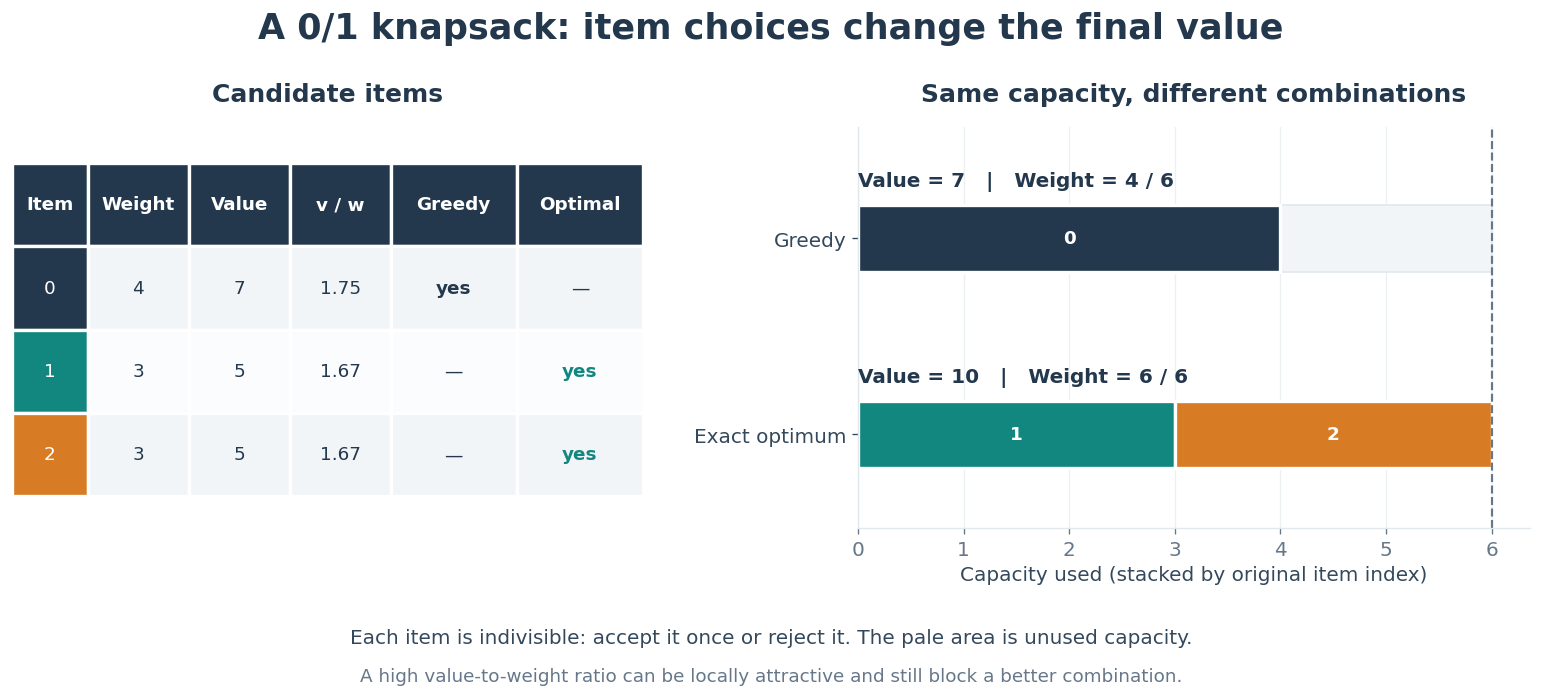

In [3]:
from experiment.baselines.methods import greedy_solution, random_solution
from experiment.eval.reference import solve as exact_solve, fractional_upper_bound
from analysis.notebook_visuals import knapsack_example_figure

toy = {'weights': [4, 3, 3], 'values': [7, 5, 5], 'capacity': 6,
       'n': 3, 'item_order': [0, 1, 2]}
greedy_toy, exact_toy = greedy_solution(toy), exact_solve(toy)
display(pd.DataFrame({'Item': ['A', 'B', 'C'], 'Weight': toy['weights'],
                      'Value': toy['values'], 'Value / weight': np.array(toy['values']) / toy['weights']}))
print('Greedy value:', greedy_toy.value, '| exact optimum:', exact_toy.value)
assert (greedy_toy.value, exact_toy.value) == (7, 10)
knapsack_example_figure(toy, greedy_toy.selected_indices, exact_toy.selected_indices)
plt.show()

**Interpretation.** Greedy's gap is 30% on this deliberately simple example.
An optimal sequential policy would skip A, include B, then include C. Alternatively,
a higher-level learner could select an algorithm that discovers B+C. These are two
different action spaces, even though the final optimization objective is the same.

## 3. Project workflow and research progression

The project developed in stages so that errors could be diagnosed before training:
data preparation → feasibility and exact references → simple baselines → DQN →
strategy selection → fresh-instance follow-up → independent verification.
The original DQN result was retained even though it did not beat greedy. It motivated
a change in the **learning problem**, from constructing every item decision to choosing
an optimization strategy. The follow-up configuration was frozen before inspecting its
test outcomes.

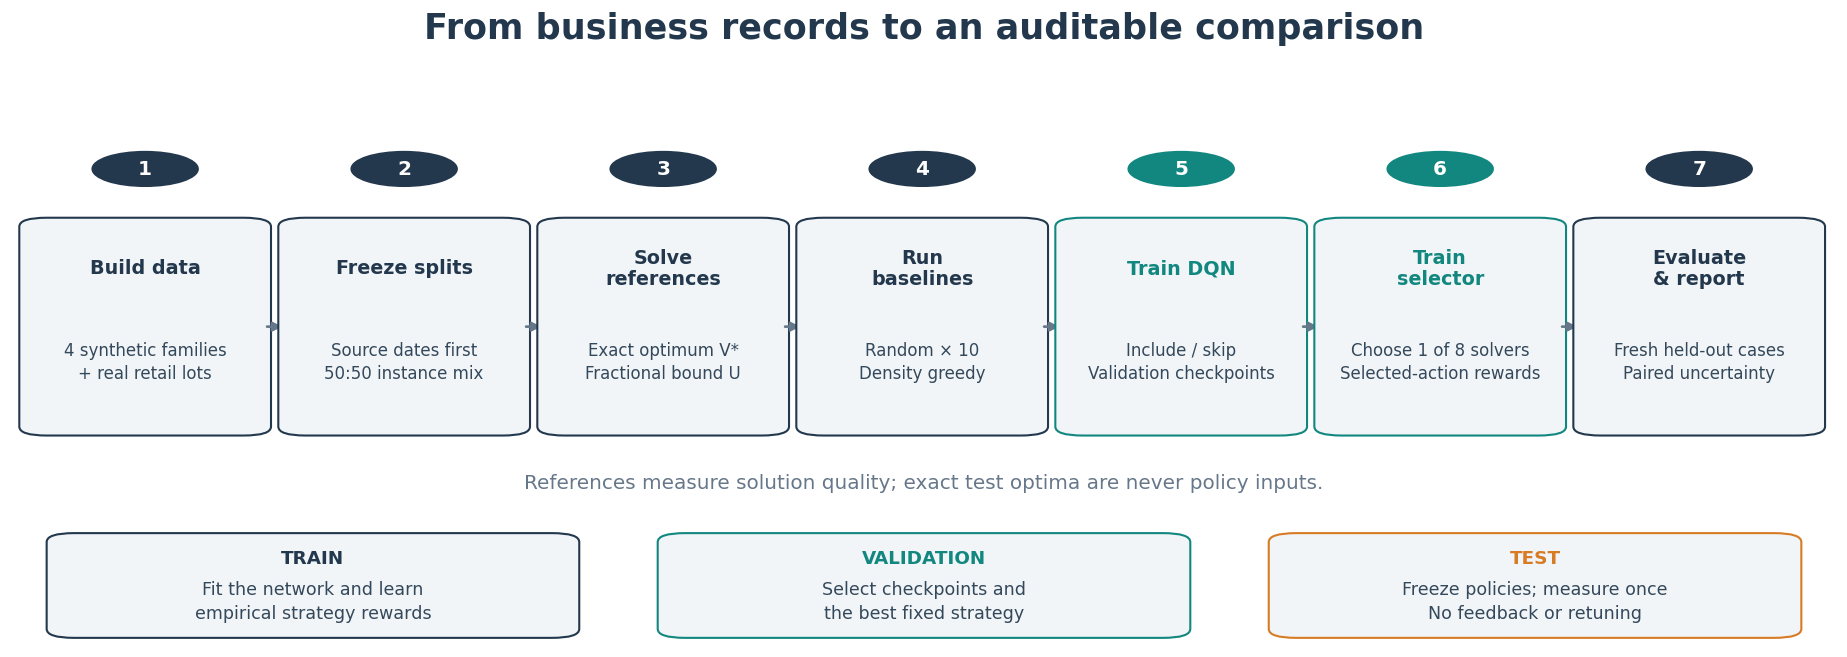

In [4]:
from analysis.notebook_visuals import workflow_figure
workflow_figure()
plt.show()

<a id="data"></a>
## 4. Data: synthetic instances and public business records

The project uses two complementary sources. **Synthetic data** controls distribution shape,
problem size and resource pressure. **Real-derived data** brings variation from public
transactions into the same optimization model. The 50:50 ratio is measured by **complete
knapsack instances**, not item rows. A single instance comes from one source; we do not
combine synthetic and transaction items inside one knapsack.

### 4.1 Public data acquisition

The core public source is [UCI Online Retail](https://archive.ics.uci.edu/dataset/352/online+retail),
contributed by Daqing Chen and covering a UK online retailer from December 2010 to December
2011. The dataset is distributed under CC BY 4.0. The acquisition pipeline downloaded the
public archive, verified file hashes, read the spreadsheet and recorded an audit trail.

Relevant fields are quantity, unit price, invoice identifier, stock code and date. We adapt
a positive product transaction line into an indivisible fulfillment lot:

| Knapsack quantity | Transformation | Interpretation |
|:--|:--|:--|
| Weight/resource demand | `Quantity` | Handling units, not measured freight mass |
| Value | `round_half_up(100 × Quantity × UnitPrice)` | Integer pence of sales value, not profit |
| Capacity | `floor(alpha × sum(weights))` | Imposed experimental handling budget |
| Provenance | Original source-row ID and invoice/date | Audit and leakage prevention |

Warehouse allocation and air cargo motivate the research, but **no measured airline cargo
dataset is used in the completed experiment**. Public transactions are a warehouse-allocation
proxy, not observations of actual accept/reject loading decisions.

### 4.2 Cleaning rules and audit

We remove cancelled transactions, invalid/nonpositive resource or price values, invalid stock
codes, exact duplicate records, and records that fail required-field, timestamp, integer-quantity
or positive-pence checks. Removal reasons are applied in a fixed order and are **exclusive**:
each removed row is counted once. Customer identity is not a policy input; missing unused fields
do not automatically invalidate a lot. Large positive observations are retained because tail
behavior is part of the experiment.

,Rows removed
First failing rule,
cancellation_invoice,9288
exact_duplicate_record,5221
invalid_stock_code,2379
nonpositive_quantity_or_price,2517


Raw: 541,909; retained: 522,504; removed: 19,405


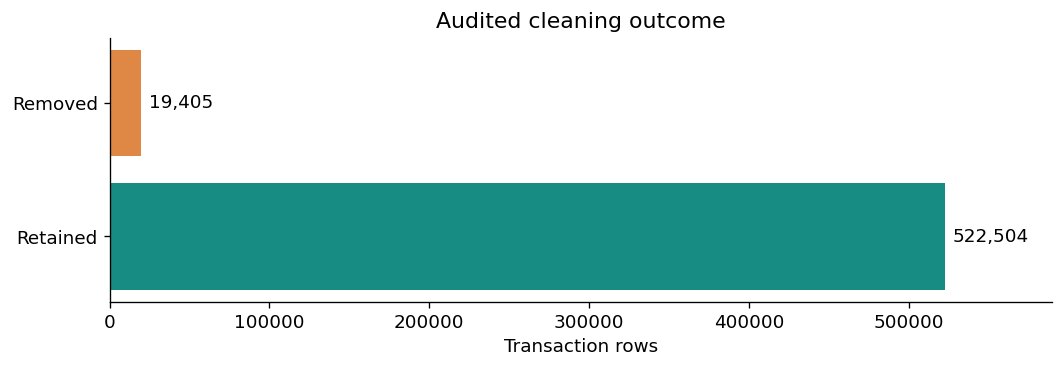

In [5]:
dropped = pd.Series(audit['cleaning']['dropped_by_reason'], name='Rows removed')
display(dropped[dropped > 0].rename_axis('First failing rule').to_frame())
assert audit['raw_rows'] == audit['kept_rows'] + dropped.sum()
print(f"Raw: {audit['raw_rows']:,}; retained: {audit['kept_rows']:,}; removed: {dropped.sum():,}")
fig, ax = plt.subplots(figsize=(9, 3.2))
bars = ax.barh(['Retained', 'Removed'], [audit['kept_rows'], dropped.sum()],
              color=['#168c82', '#df8845'])
ax.bar_label(bars, labels=[f'{audit["kept_rows"]:,}', f'{dropped.sum():,}'], padding=5)
ax.set(xlabel='Transaction rows', title='Audited cleaning outcome', xlim=(0, 590000))
fig.tight_layout(); plt.show()

**Observed audit:** 541,909 raw rows become 522,504 valid lots. The 19,405 removals comprise
9,288 cancellations, 2,517 nonpositive quantity/price rows, 2,379 invalid stock-code rows and
5,221 exact duplicates. Zero rows fail the other checks in this frozen run; the checks still
exist in the pipeline.

The following small sample comes from the first eight cleaned rows, not from an outcome-selected
subset. Decimal arithmetic avoids binary floating-point rounding surprises when converting
monetary values to integer pence.

In [6]:
from decimal import Decimal, ROUND_HALF_UP
lots = pd.read_csv(BUNDLE / 'real_lot_sample.csv', dtype={'unit_price': str})
lots['recomputed_pence'] = [
    int((Decimal(p) * Decimal(int(q)) * 100).quantize(Decimal('1'), rounding=ROUND_HALF_UP))
    for p, q in zip(lots.unit_price, lots.quantity_w)]
assert (lots.recomputed_pence == lots.value_pence).all()
display(lots[['source_row_id', 'invoice_date', 'quantity_w', 'unit_price', 'value_pence']])

,source_row_id,invoice_date,quantity_w,unit_price,value_pence
0,0,2010-12-01 08:26:00,6,2.55,1530
1,1,2010-12-01 08:26:00,6,3.39,2034
2,2,2010-12-01 08:26:00,8,2.75,2200
3,3,2010-12-01 08:26:00,6,3.39,2034
4,4,2010-12-01 08:26:00,6,3.39,2034
5,5,2010-12-01 08:26:00,2,7.65,1530
6,6,2010-12-01 08:26:00,6,4.25,2550
7,7,2010-12-01 08:28:00,6,1.85,1110


### 4.3 Chronological splitting and leakage prevention

We assign each invoice to its earliest transaction calendar date, then split whole dates
chronologically. The declared 70/15/15 policy refers to **ordered source dates**, not a
random 70/15/15 row split. No invoice or source row crosses train, validation and test.

| Source pool | Date range | Dates | Cleaned lots | Invoices |
|:--|:--|--:|--:|--:|
| Train | 2010-12-01 to 2011-08-23 | 213 | 299,597 | 12,068 |
| Validation | 2011-08-24 to 2011-10-17 | 46 | 88,796 | 3,191 |
| Test | 2011-10-18 to 2011-12-09 | 46 | 134,111 | 4,514 |

To construct a real-derived instance, choose an eligible date and sample n distinct lots
without replacement within that instance. A source row can be reused in different instances
from the **same** partition. Therefore, instances are not all statistically independent:
later uncertainty calculations resample real source dates as clusters.

| Original optimization partition | Synthetic | Real-derived | Total | Purpose |
|:--|--:|--:|--:|:--|
| Training | 6,000 | 6,000 | 12,000 | Learn policies |
| Validation | 1,200 | 1,200 | 2,400 | Select checkpoints and fixed control |
| Main test | 1,200 | 1,200 | 2,400 | Evaluate methods |
| E3: n=500 | 300 | 300 | 600 | Size generalization |
| E4: extreme skew | 300 | 0 | 300 | Distribution stress |

**E4b** in the original study is a subset of 691 real main-test instances containing a lot
above training-only tail thresholds: quantity >100 or unit price >£16.95. It is not an
additional independent dataset. The portfolio follow-up reports main, E3 and E4 separately.

,synthetic,real,total
test,1200,1200,2400
train,6000,6000,12000
validation,1200,1200,2400


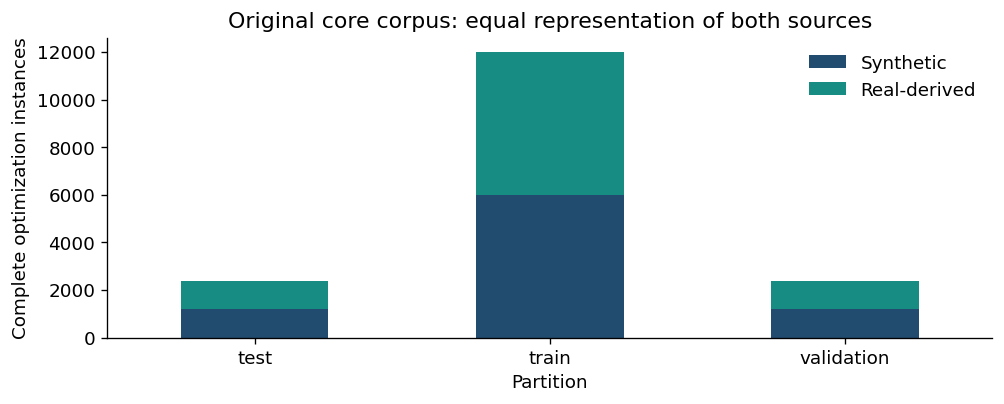

In [7]:
split_counts = pd.DataFrame(manifest['counts']).T[['synthetic', 'real', 'total']]
display(split_counts)
assert (split_counts.synthetic == split_counts.real).all()
ax = split_counts[['synthetic', 'real']].plot.bar(
    stacked=True, color=['#214c70', '#168c82'], figsize=(8.5, 3.5), rot=0)
ax.set(xlabel='Partition', ylabel='Complete optimization instances',
       title='Original core corpus: equal representation of both sources')
ax.legend(['Synthetic', 'Real-derived'], frameon=False)
plt.tight_layout(); plt.show()

## 5. Synthetic distributions and stress design

A single easy distribution can hide algorithm weaknesses. We deliberately vary the shape
of weights and values while holding the objective and constraints fixed.

| Family | Weight generation | Value generation | What it probes |
|:--|:--|:--|:--|
| Uniform | Integer uniform 1–100 | Independent integer uniform 1–100 | Broad unstructured variation |
| Normal | Normal(50,15²), half-up rounded, clipped to 1–100 | Independent draw with the same rule | Concentration around typical items |
| Correlated | Integer uniform 1–100 | max(1, weight + integer noise from −10 to 10) | Similar value densities |
| Skewed | Usually 1–20; rare weights 200–500 | weight × density; usually density 1–5, rare density 30–60 | Large items and high-value outliers |

In the skewed family, `k=max(1,floor(0.05n+0.5))` indices receive heavy weights and an
independently selected k indices receive high densities. The two index sets **can overlap**.
E4 uses n=200 and two indices per rare set, heavy weights 500–2,000 and densities 100–200.
This is **item-distribution imbalance**, not class imbalance in a classification dataset.

Main sizes are 20, 50, 100 and 200, each with three alpha values. E3 uses n=500 without
training on that size. Seeded generation, separate item/order streams and canonical hashes
make the instances reproducible. The actual generator derives seeds by BLAKE2b from split,
family, size, capacity ratio, index, resampling attempt and stream. Numeric labels such as
1001/2001/3001 are documentary identifiers, not the actual input to that hash function.

The next figure generates small **illustrative samples**, not additional test evidence.
The logarithmic value axis makes the skewed family's large values visible.

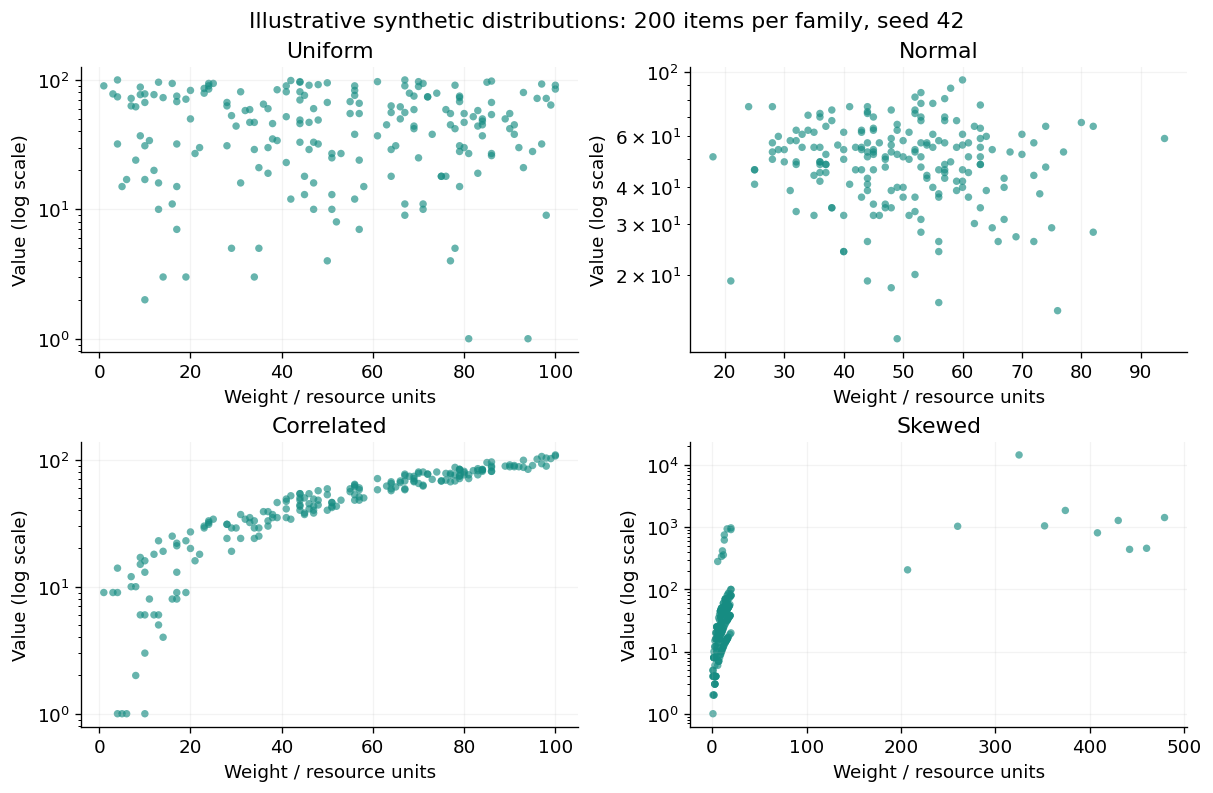

In [8]:
from experiment.data.generate.families import generate_items
families = ['uniform', 'normal', 'correlated', 'skewed']
fig, axes = plt.subplots(2, 2, figsize=(10, 6.5), layout='constrained')
for ax, family in zip(axes.flat, families):
    w, v = generate_items(family, n=200, seed=42)
    ax.scatter(w, v, s=20, color='#168c82', alpha=.65, edgecolors='none')
    ax.set(title=family.capitalize(), xlabel='Weight / resource units',
           ylabel='Value (log scale)', yscale='log')
    ax.grid(alpha=.15)
fig.suptitle('Illustrative synthetic distributions: 200 items per family, seed 42')
plt.show()

## 6. References, metrics and fair comparisons

### 6.1 Exact reference: integer dynamic programming

A small example can be checked by enumerating all subsets, but the number of subsets is
$2^n$. For the integer capacities in this corpus, dynamic programming is practical.
In the familiar at-most-capacity formulation,
$$D(i,c)=\max\{D(i-1,c),\;D(i-1,c-w_i)+v_i\},$$
with the second option available only when the item fits. This yields pseudo-polynomial
time $O(nC)$. The repository uses an equivalent exact-used-capacity table, then reconstructs
and verifies the selected set. Every stored reference is certified; no timeout fallback occurs.

The exact solver is an **evaluation reference**, not a training teacher. We do not feed
its optimal sets or values to the DQN or contextual bandit as labels.

### 6.2 Two denominators that must not be confused

- $V^*$: exact integer optimum, used for the primary evaluation gap.
- $U$: fractional-knapsack upper bound, obtained by permitting the final item to be split.
  It is computable from input data and satisfies $V\leq V^*\leq U$.

$$\text{Exact gap}(\%)=100\frac{V^*-V}{V^*},\qquad
  \text{normalized reward}=\frac{V}{U}.$$

Even a globally optimal integer solution can have V/U below one. The stored `upper_bound`
remains U after the reference is certified; certification does not turn it into V*.
Zero-optimum cases require separate treatment in percentage metrics; none occurs in the
formal corpora. A learning reward and an evaluation metric serve different purposes.

In [9]:
U = fractional_upper_bound(toy['weights'], toy['values'], toy['capacity'])
metric_demo = pd.DataFrame({'Solution': ['Greedy', 'Exact integer optimum'],
                           'Value': [greedy_toy.value, exact_toy.value]})
metric_demo['Exact gap (%)'] = 100 * (exact_toy.value - metric_demo.Value) / exact_toy.value
metric_demo['V / U'] = metric_demo.Value / float(U)
display(metric_demo)
print(f'For this example: V* = {exact_toy.value}, U = {U} = {float(U):.4f}')
assert greedy_toy.value <= exact_toy.value <= U

,Solution,Value,Exact gap (%),V / U
0,Greedy,7,30.0000,0.6774
1,Exact integer optimum,10,0.0000,0.9677


For this example: V* = 10, U = 31/3 = 10.3333


### 6.3 Aggregation and uncertainty

We average the ten random trials **within each instance** before aggregating quality.
We average synthetic and real source means with equal weight when both exist; this avoids
one source dominating due to sample-count changes. Synthetic-only E4 has a synthetic mean.
Raw values from different sources are not pooled as if synthetic units and pence were
interchangeable monetary quantities.

We report feasibility, exact gap, V/U, improvement relative to greedy, win/tie/loss rates,
runtime, learning cost, and robustness. The three model seeds are reported individually and
as a descriptive mean. That mean is **not** a deployment policy that tries all seeds and
keeps the best answer.

For uncertainty, compare algorithms on the same instances. The paired bootstrap resamples
whole real source dates and synthetic instances within family/size/alpha cells, then combines
source means equally. Its 95% intervals describe data-sampling variation **conditional on the
fitted models**. Three-seed sample standard deviation describes a different source of variation.

<a id="methods"></a>
## 7. Baselines: random and density greedy

**Random selection.** Follow the stored item order. When an item currently fits, include it
with probability 0.5; otherwise skip it. Ten independently seeded trials are averaged. This
establishes a low-information baseline rather than a competitive heuristic.

**Density greedy.** Sort by descending value/weight. Ties use lower weight, then original
item index. Include each fitting item and **continue scanning after an item does not fit**.
Ratios are compared by integer cross multiplication in the implementation. It is fast and
often effective, but the indivisibility of items prevents a general optimality guarantee.

The code below calls the tested implementations. It is a small live illustration; the
formal tables use the full held-out corpus and saved trial seeds.

In [10]:
random_values = [random_solution(toy, seed=s).value for s in range(10)]
display(pd.DataFrame({'Trial': range(10), 'Random value': random_values}))
print('Random mean:', np.mean(random_values))
print('Greedy:', greedy_toy.value, '| optimum:', exact_toy.value)
print('We report the random mean, not max(random_values).')

,Trial,Random value
0,0,5
1,1,7
2,2,5
3,3,7
4,4,7
5,5,0
6,6,5
7,7,7
8,8,7
9,9,7


Random mean: 5.7
Greedy: 7 | optimum: 10
We report the random mean, not max(random_values).


## 8. First RL formulation: sequential DQN

The original agent constructs a subset by processing each item once in the stored order.
It sees information about all remaining items, not only the current item.

| RL element | Knapsack interpretation |
|:--|:--|
| State | Remaining items, current position, remaining capacity |
| Actions | Skip or include current item |
| Feasibility | Mask include whenever weight exceeds remaining capacity |
| Reward | Included value divided by the sum of all original item values; zero for skip |
| Episode | Ends after the last item |
| Discount | gamma = 1, so total episode reward tracks selected value |

A shared two-layer 64-unit item encoder reads normalized weight and value. Mean/max pooling
summarizes the unprocessed suffix. A 128-unit head receives the pooled features and current
context, then predicts Q-values for the two actions. The model has **21,762 parameters**.
Source names and instance IDs are not neural prediction inputs.

The temporal-difference target is
$$y=r+\gamma\max_{a'\;\mathrm{feasible}}Q_{\mathrm{target}}(s',a'),$$
with no bootstrap term after termination. Replay and a target network help stabilize training.
This is ordinary DQN, **not Double DQN**. The general neural action-value idea follows
[Mnih et al.](https://www.nature.com/articles/nature14236); the knapsack representation is
specific to this project.

### 8.1 Frozen training settings

| Setting | Value |
|:--|:--|
| Training seeds | 0, 1, 2 |
| Budget | 300,000 requested transitions; 300,440 actual per seed after completing a balanced block |
| Optimizer / learning rate | Adam / 0.0003 |
| Loss / gradient clipping | Huber / global norm 10 |
| Replay / minibatch | 100,000 transitions / 64, with 32 from each source |
| Warm-up / update interval | 5,000 transitions / every 4 transitions |
| Target-network copy | Every 2,000 transitions |
| Epsilon | 1.0 to 0.05 over 150,000 transitions |
| Checkpoint criterion | Highest validation source-balanced V/U; earlier checkpoint on exact ties |
| Evaluation | Fixed feasible argmax policy, no exploration |

Balanced sampling covered all source/size pairs, but repeated sampling visited only about
2,800 distinct training instances per seed. The three CPU runs took roughly 20.5 minutes
of concurrent wall time each; this is not the sum of isolated training times.

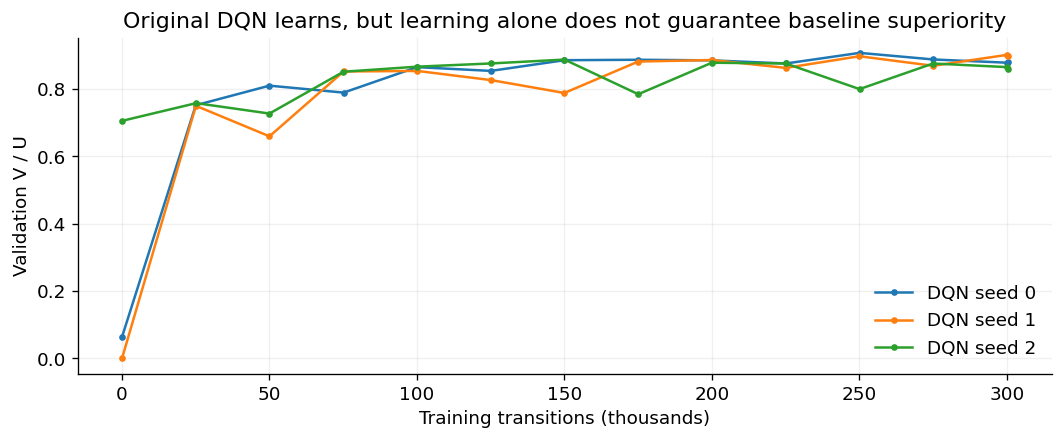

In [11]:
curves = pd.DataFrame(load_json(BUNDLE / 'dqn_validation.json'))
curves[['step', 'score']] = curves[['step', 'score']].astype(float)
fig, ax = plt.subplots(figsize=(9, 3.8))
for seed, group in curves.groupby('seed'):
    ax.plot(group.step / 1000, group.score, marker='o', ms=3, label=f'DQN seed {seed}')
ax.set(xlabel='Training transitions (thousands)', ylabel='Validation V / U',
       title='Original DQN learns, but learning alone does not guarantee baseline superiority')
ax.legend(frameon=False); ax.grid(alpha=.18)
fig.tight_layout(); plt.show()

### 8.2 What the original experiment taught us

On the **original** 2,400-instance main test, random, greedy and DQN had mean exact gaps
of **43.089%, 1.159% and 9.521%**, respectively. DQN improved substantially over random but
did not beat greedy. At n=500 its gap increased to 31.641%.

Plausible explanations include limited distinct training exposure, information compression
by pooling, and distribution changes in normalized features at larger sizes. These are
hypotheses supported by the formulation, not causal conclusions from an ablation study.
Greedy already exploits a highly informative ratio in this static single-resource task.
A larger network or additional training is not guaranteed to overturn that advantage.

This prompted a practical research question: **can the learner use successful optimization
procedures as actions, instead of learning every inclusion decision from scratch?**
We preserve the original negative result and evaluate the revised formulation separately.

## 9. Main method: RL learns to select an optimization strategy

The new agent observes instance statistics and selects one complete solver. It receives
a reward after that solver returns a feasible solution. This is a **contextual bandit**,
a one-step RL formulation: there is no sequence of capacity states at the selector level,
and no Bellman bootstrap is needed in its update.

The context/action/reward viewpoint is related to the general contextual-bandit formulation
described by [Li et al.](https://arxiv.org/abs/1003.0146). Our implementation is a tabular
epsilon-greedy learner with global-mean shrinkage, not a reproduction of their LinUCB algorithm.

**A crucial distinction:** the candidate algorithms are the agent's actions. Seven candidates
are hand-designed heuristics; one is the frozen DQN. The upper-level policy is learned even
though most lower-level actions execute non-learning algorithms.

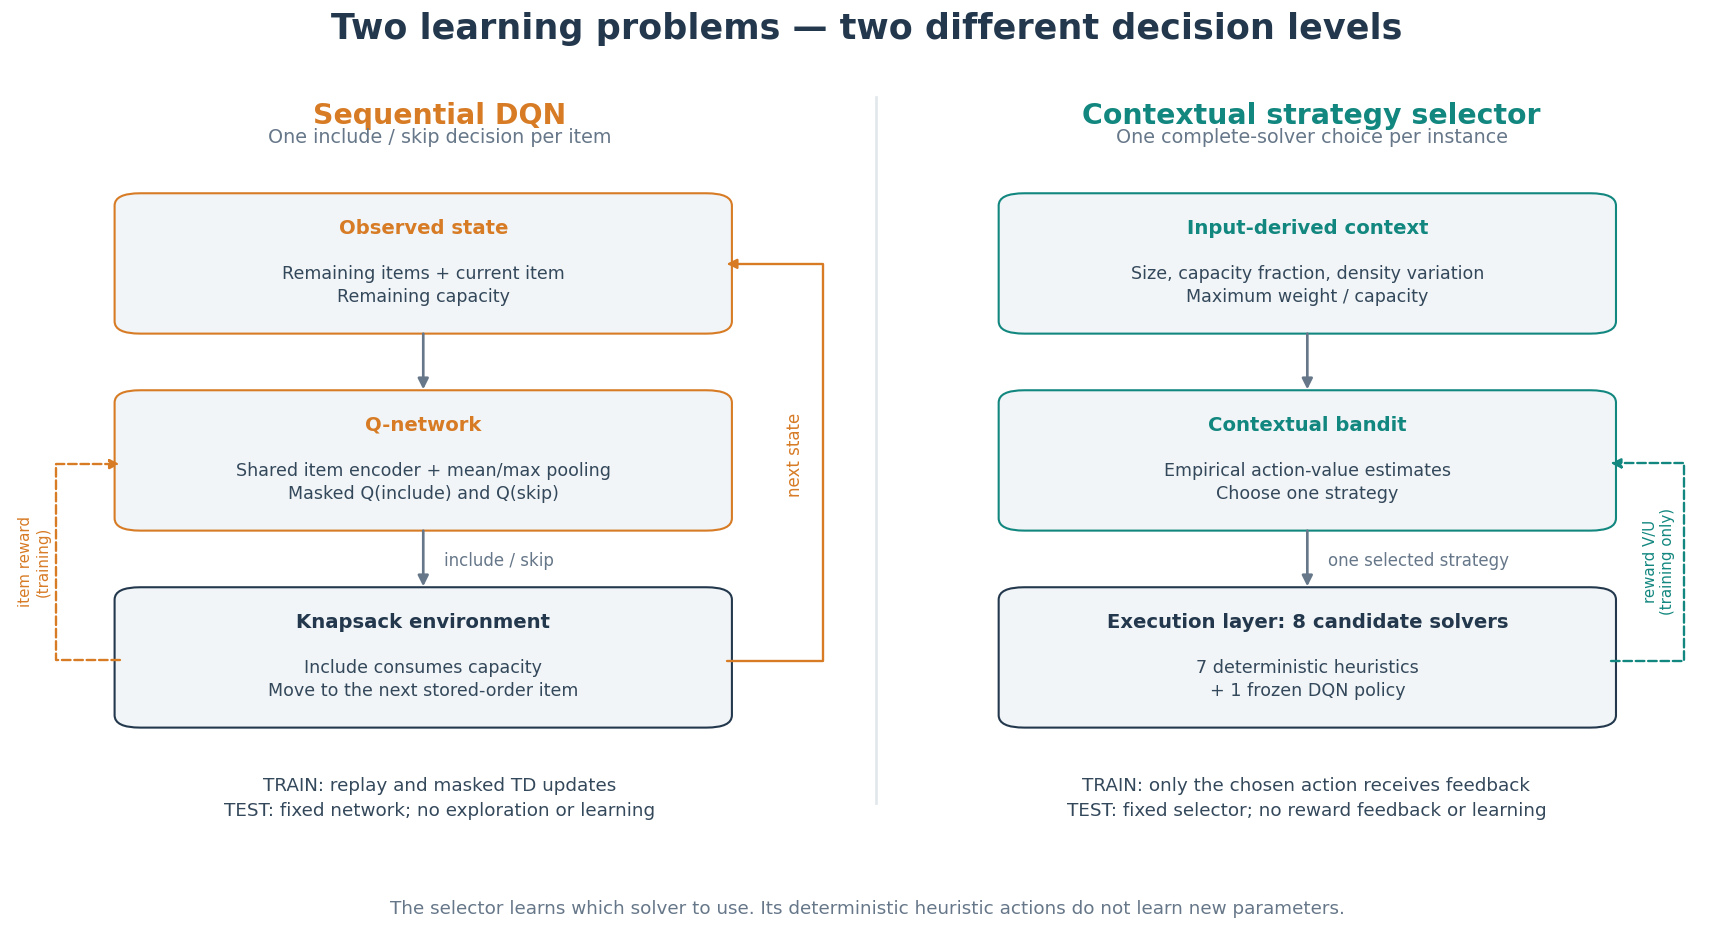

In [12]:
from analysis.notebook_visuals import learning_architecture_figure
learning_architecture_figure()
plt.show()

### 9.1 The eight candidate actions

| Candidate | Construction rule | Why include it? |
|:--|:--|:--|
| Density greedy | Decreasing value/weight | Strong original baseline |
| Value first | Decreasing value | Give priority to valuable indivisible items |
| Light first | Increasing weight | Leave room for many small items |
| Value/sqrt(weight) | A softer penalty for weight | Alternative trade-off between value and size |
| Adapted 1/e threshold | Observe/reject an initial prefix, then require its maximum density | Test an observation-based strategy |
| Seeded greedy | Force one of up to eight seeds, then refill by density | Explore alternatives to the first greedy choice |
| Exchange repair | Try up to eight valuable omitted items with removal/refill | Repair unfavorable greedy combinations |
| Frozen DQN seed 0 | Original learned include/skip policy | Retain the best original validation checkpoint |

Seeded greedy uses the union of the top four items by value and top four by density.
Exchange repair independently tries each candidate from the original greedy set, removing
selected low-density items until it fits and then refilling. Neither is an unbounded search.
Both retain ordinary greedy as an option and therefore cannot return a lower value.

### 9.2 Why the 1/e idea needs an explicit test

Let `m=floor(n/e)`. Our adapted candidate rejects the first m stored-order items, records
the largest density in that prefix, then accepts feasible later items whose density meets
the threshold. For n=200 it observes 73 items. Its goal here is subset value, not the probability
of choosing a single best item. Classical secretary guarantees do not transfer unchanged to
weighted knapsack; [knapsack-secretary research](https://www.microsoft.com/en-us/research/publication/a-knapsack-secretary-problem-with-applications/)
explicitly studies the different assumptions.

On this offline corpus the rule often rejects too many useful items. It is retained as an
honest candidate comparison, not tuned after seeing test results. An action library may
include a poor action; successful learning should discover when to avoid it.

In [13]:
from portfolio.strategies import candidate_names, solve_strategy
names = list(candidate_names())
candidate_demo = pd.DataFrame([
    {'Candidate': name, 'Value': (s := solve_strategy(name, toy)).value,
     'Weight used': s.weight_used, 'Chosen original indices': list(s.selected_indices)}
    for name in names])
display(candidate_demo)
print('This is a teaching example, not a comparison over the test distribution.')

,Candidate,Value,Weight used,Chosen original indices
0,greedy_density,7,4,[0]
1,value_first,7,4,[0]
2,light_first,10,6,"[1, 2]"
3,density_sqrt,7,4,[0]
4,one_e_threshold,0,0,[]
5,seeded_greedy8,10,6,"[1, 2]"
6,swap_repair8,10,6,"[1, 2]"


This is a teaching example, not a comparison over the test distribution.


### 9.3 Context: what information can the learner use?

The context is a tuple of four bins, all computed from the known input:

| Feature | Meaning | Bin boundaries |
|:--|:--|:--|
| Number of items | Problem scale | 30, 75, 150 |
| C / sum(weights) | Capacity pressure | 0.375, 0.625 |
| Density standard deviation / mean | Heterogeneity in value per resource unit | 0.5, 1.5 |
| max(weight) / C | Dominance of a large item | 0.1, 0.5 |

These boundaries define at most 108 context cells. Source labels, family names, IDs, exact
optima and candidate outcomes are excluded. Zero-capacity and empty examples have explicit
numerical guards. For an unobserved context, the model falls back to learned global action
means. Binning reduces sample requirements and is easy to inspect, but it can merge instances
with different best strategies.

### 9.4 Learning from selected-action rewards

For context c and action a, let $N_{c,a}$ be the number of observed rewards and $S_{c,a}$
their sum. Let $\mu_a$ be the global observed mean for that action. We use
$$\widehat Q(c,a)=\frac{S_{c,a}+5\mu_a}{N_{c,a}+5},\qquad R=V/U.$$

The five global-mean pseudo-observations stabilize sparse context estimates. With probability
epsilon, training explores a random action; otherwise it selects the highest estimated reward.
**Only the chosen action's reward updates the model.** During evaluation, exploration is zero
and no test reward is fed back into the policy.

```text
For each training instance:
    compute context from input statistics
    choose a strategy using epsilon-greedy exploration
    obtain that strategy's solution value
    normalize by the input-derived fractional bound
    update only the chosen context–action count and reward sum
After each epoch:
    evaluate the fixed policy on validation; save a better checkpoint
```

In [14]:
from portfolio.bandit import Bandit, context_key
demo_inputs = load_json(BUNDLE / 'demo_instances.json')
display(pd.DataFrame([
    {'Source (display only)': i['source'], 'Family (display only)': i.get('family'),
     'n': i['n'], 'Capacity': i['capacity'],
     'Model context': context_key(i, config['context_bins'])}
    for i in demo_inputs]))
print('Source/family columns are shown for explanation; context_key does not use them.')

,Source (display only),Family (display only),n,Capacity,Model context
0,synthetic,uniform,20,536,"(0, 1, 1, 1)"
1,synthetic,normal,20,459,"(0, 1, 0, 1)"
2,synthetic,correlated,20,462,"(0, 1, 1, 1)"
3,synthetic,skewed,20,348,"(0, 1, 2, 2)"
4,real,NaN,20,64,"(0, 1, 1, 1)"
5,real,NaN,20,39,"(0, 1, 1, 2)"
6,real,NaN,20,70,"(0, 1, 1, 1)"
7,real,NaN,20,43,"(0, 1, 1, 1)"


Source/family columns are shown for explanation; context_key does not use them.


### 9.5 A small learning experiment you can run live

This separate **teaching simulation** has two known types of tiny knapsack instance and
only two actions: `value_first` and `light_first`. In type A, light-first finds the better
combination. In type B, value-first does. We begin with an empty learner, show one selected
reward per interaction, and ask whether different contexts learn different choices.

The instances below were designed to illustrate complementarity. They are not sampled
held-out results and do not replace the formal experiment. The demonstration uses the same
`Bandit` update implementation, but a smaller action space and a separate random seed.

In [15]:
cases = [toy, {'weights': [2, 3, 3], 'values': [2, 100, 100],
               'capacity': 6, 'n': 3, 'item_order': [0, 1, 2]}]
teaching_arms = ['value_first', 'light_first']
teaching_model = Bandit(teaching_arms, prior_strength=5)
keys = [context_key(i, config['context_bins']) for i in cases]
assert keys[0] != keys[1]
rng = np.random.default_rng(2026)
snapshots = []
for step in range(1000):
    k = step % 2
    action = int(rng.integers(2)) if rng.random() < .3 else teaching_model.predict(keys[k])
    value = solve_strategy(teaching_arms[action], cases[k]).value
    upper = fractional_upper_bound(cases[k]['weights'], cases[k]['values'], cases[k]['capacity'])
    teaching_model.update(keys[k], action, float(value / upper))
    if (step + 1) % 50 == 0:
        snapshots.append([step + 1, *teaching_model.estimates(keys[0]),
                          *teaching_model.estimates(keys[1])])
display(pd.DataFrame({'Context': ['A', 'B'],
                     'Learned choice': [teaching_arms[teaching_model.predict(k)] for k in keys]}))
assert [teaching_model.predict(k) for k in keys] == [1, 0]

,Context,Learned choice
0,A,light_first
1,B,value_first


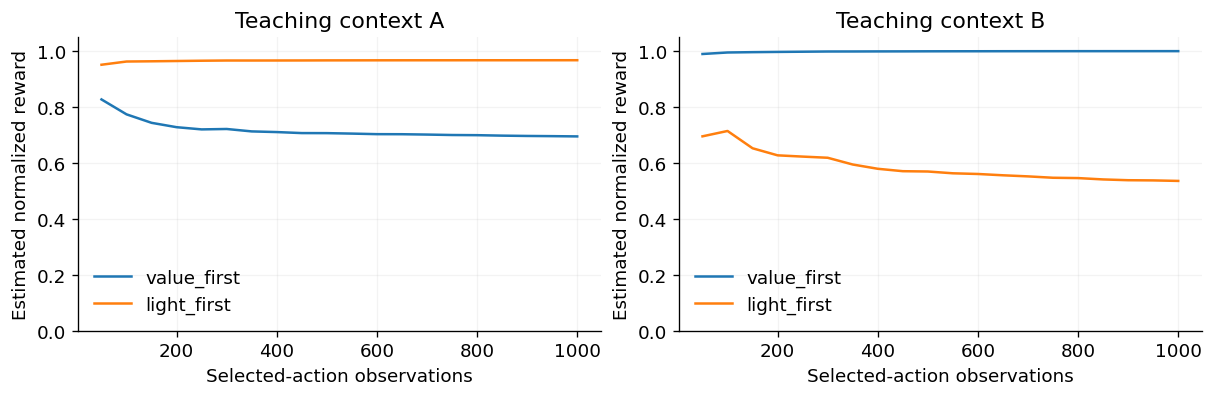

In [16]:
history = np.array(snapshots)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.2), layout='constrained')
for k, ax in enumerate(axes):
    for action, label in enumerate(teaching_arms):
        ax.plot(history[:, 0], history[:, 1 + 2*k + action], label=label)
    ax.set(title=f'Teaching context {"AB"[k]}', xlabel='Selected-action observations',
           ylabel='Estimated normalized reward', ylim=(0, 1.05))
    ax.legend(frameon=False); ax.grid(alpha=.15)
plt.show()

**What this demonstrates:** a reward-based selector can associate different input contexts
with different useful algorithms. There are no labels saying which action is optimal in the
update. This is a mechanism demonstration, not evidence that the formal model always chooses
the best candidate. That question requires a held-out comparison.

## 10. Formal strategy-selection training and experimental design

The formal learner has eight actions, the fixed four-feature context, and three training
seeds. Each run makes ten passes over the original 12,000 training instances. Each pass
shuffles the two sources separately and alternates them. Thus every instance is visited
once per epoch and every run has **120,000 selected-action observations**, split equally
between sources. Epsilon decreases linearly from 1.0 to 0.1 across the run.

A cache precomputes all candidate outcomes to make simulation efficient. The learner still
receives only the indexed reward of the selected action at each update. This is **selected-feedback
training in a simulator**, not live bandit data collection. Cache construction cost is counted.
DP optima are not used in those updates.

Validation is evaluated after every epoch using source-balanced V/U. The earlier checkpoint
wins exact ties. All runs finish their full budget even if a prior checkpoint is selected.
A separate fixed-action control chooses the single strategy with the highest validation score.
No follow-up test outcomes choose hyperparameters, strategy rules, checkpoints or training seeds.

| Item | Formal setting |
|:--|:--|
| Training / validation | Original 12,000 / 2,400 instances |
| Seeds | 0, 1, 2 |
| Observations | 120,000 per seed; 60,000 from each source |
| Context estimator | Tabular observed means with five global-mean pseudo-observations |
| Reward | Final selected value / fractional bound |
| Validation interval | Every epoch |
| Test behavior | Frozen deterministic highest-score action |
| New holdout | Main 2,400; E3 600; E4 300 |

This is a system-level comparison. The DQN and selector have different state/action spaces,
training exposure and computational work. It is not an equal-budget ablation proving one
neural architecture superior to another.

,Seed,Total observations,Selected step,Best validation V/U,Training loop (s)
0,0,120000,108000,0.9845,0.5296
1,1,120000,120000,0.9845,0.5240
2,2,120000,72000,0.9844,0.5147


Cache construction: 13.82 seconds
Overall follow-up training pipeline: 15.54 seconds


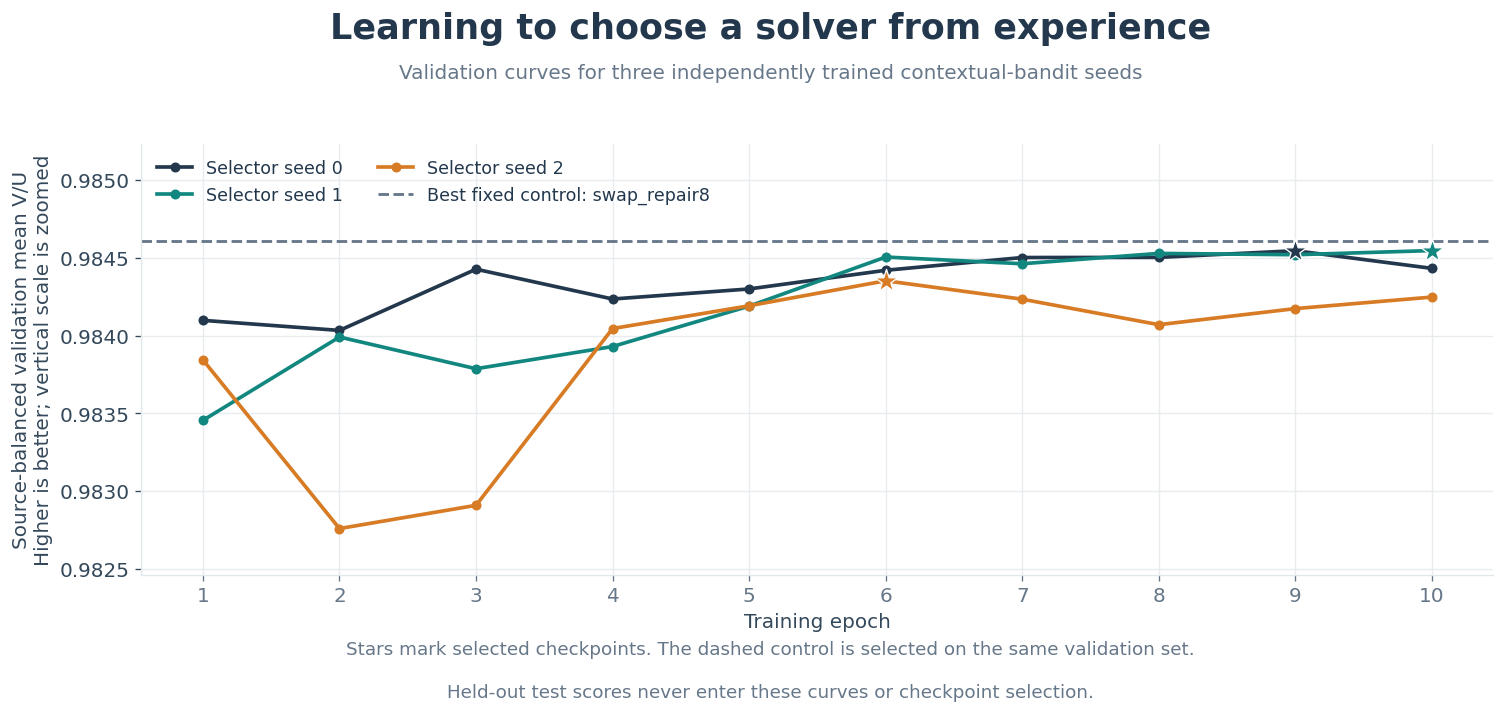

In [17]:
display(pd.DataFrame([
    {'Seed': r['seed'], 'Total observations': r['observations'],
     'Selected step': r['best_step'], 'Best validation V/U': r['best_validation_quality'],
     'Training loop (s)': r['elapsed_seconds']}
    for r in training['runs']]))
print(f"Cache construction: {training['cache_seconds']:.2f} seconds")
print(f"Overall follow-up training pipeline: {training['elapsed_seconds']:.2f} seconds")
from analysis.notebook_visuals import training_figure
training_figure(training)
plt.show()

**Reading the curves.** The selector starts learning on a strong action library, so its validation
rewards are already high early in training. Small vertical differences matter; read the axis
labels. The dashed fixed-action control explains how much performance is available without
contextual learning. Selecting an earlier checkpoint is normal and is determined on validation.

### 10.1 A fresh instance holdout, with a clear dependence caveat

The original test had already informed the research direction. We froze the follow-up design
before generating new combinations using separate namespaces and canonical deduplication
against **all 17,700 original instances**. The new 3,300 instances have no canonical duplicates
within the set or overlap with the originals.

New real-derived combinations nevertheless reuse the original test-date business pool.
The main set has 73,950 unique source rows from 46 dates; 42,156 of those rows also appear in
the original main test. There is no overlap with training or validation source rows, dates
or invoices. The follow-up is a **new instance holdout in the same business cohort**, not an
independent future business sample. Stress suites are not pooled as additional independent
main-test observations.

In [18]:
display(pd.DataFrame(holdout['counts']).T[['synthetic', 'real', 'total']])
assert holdout['dedup']['original_canonical_overlap'] == 0
overlap = holdout['overlap']['all_new_real']['original_source_pools']
assert all(v == 0 for split in ['train', 'validation'] for v in overlap[split].values())
print('Original canonical overlap:', holdout['dedup']['original_canonical_overlap'])
print('Independent new business sample:', holdout['independent_business_sample'])

,synthetic,real,total
e3_size,300,300,600
e4_tail,300,0,300
main,1200,1200,2400


Original canonical overlap: 0
Independent new business sample: False


<a id="results"></a>
## 11. Main results: does RL strategy selection improve the original baselines?

The following comparison uses **the same 2,400 follow-up main-test instances** for every
method. Half are synthetic and half real-derived. The old DQN is frozen; it is re-evaluated
on these new combinations. Lower exact gap means the selected value is closer to the
certified optimum.

This is the primary result for the seminar: an agent that learns which algorithm to use
produces substantially better solutions than the original random, greedy and DQN approaches.
It is a measured improvement on this benchmark, not a claim of universal RL superiority.

,Exact gap (%),Feasible fraction,Median time (ms),p95 time (ms)
Random (10-trial mean),42.9893,1.0000,0.0138,0.0282
Density greedy,1.3567,1.0000,0.0520,0.1416
Frozen DQN (3-seed mean),9.3742,1.0000,5.8958,12.6934
RL strategy selector (3-seed mean),0.1590,1.0000,0.2172,0.6133


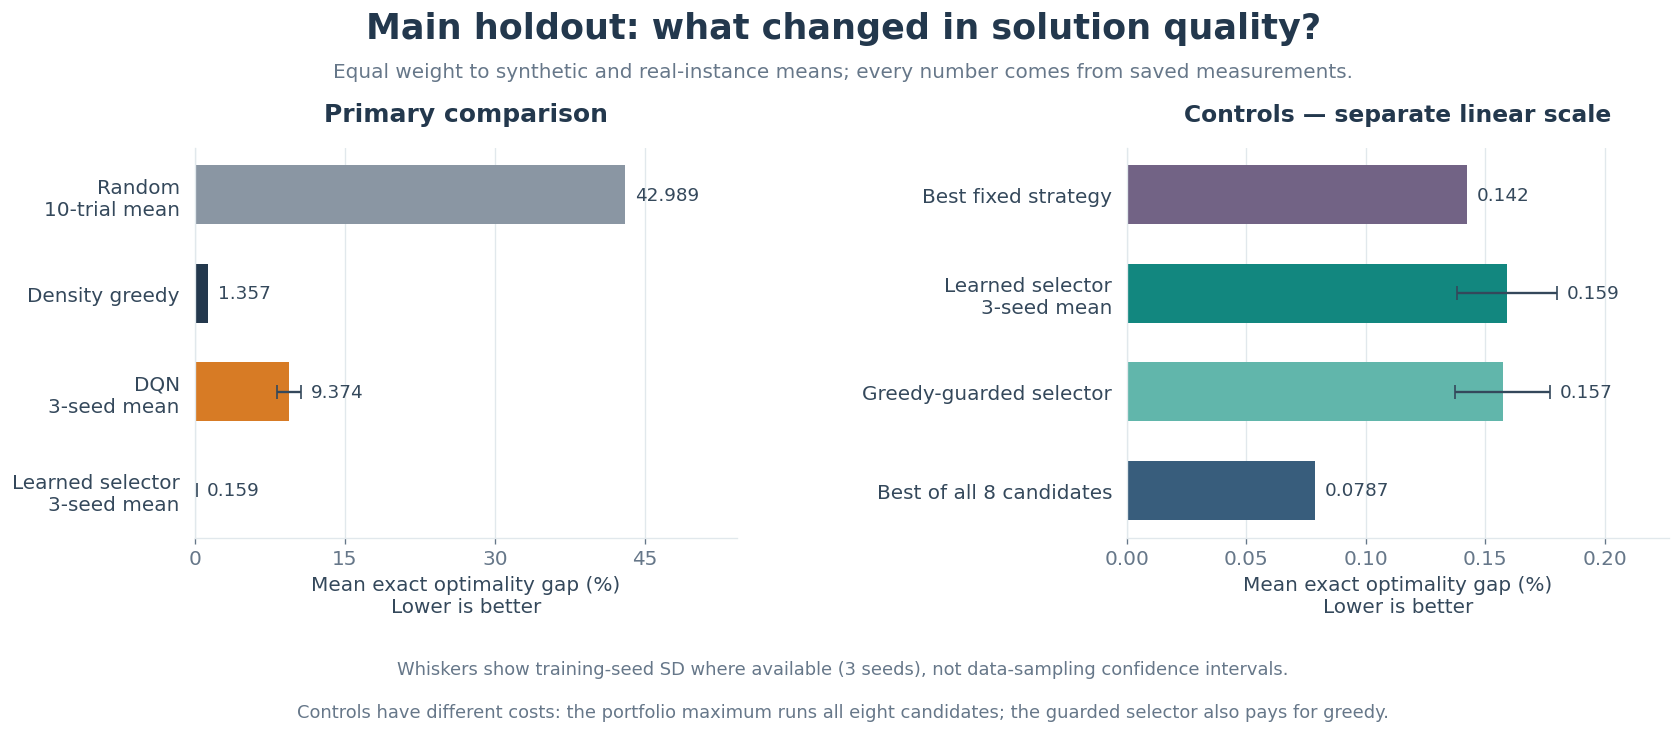

In [19]:
primary = summary.query("split == 'main' and group == 'overall'").set_index('method')
primary_methods = ['random', 'greedy_density', 'dqn_mean', 'selector_mean']
labels = {'random': 'Random (10-trial mean)', 'greedy_density': 'Density greedy',
          'dqn_mean': 'Frozen DQN (3-seed mean)', 'selector_mean': 'RL strategy selector (3-seed mean)'}
result_table = primary.loc[primary_methods, ['exact_gap_pct_mean', 'feasible_rate', 'latency_median_s', 'latency_p95_s']].copy()
result_table['latency_median_s'] *= 1000
result_table['latency_p95_s'] *= 1000
result_table.index = [labels[m] for m in primary_methods]
result_table.columns = ['Exact gap (%)', 'Feasible fraction', 'Median time (ms)', 'p95 time (ms)']
display(result_table)
assert np.isclose(primary.loc['selector_mean', 'exact_gap_pct_mean'], .1590053984006689)
from analysis.notebook_visuals import main_results_figure
main_results_figure(summary)
plt.show()

### 11.1 Interpreting the improvement

The main selector gap is **0.159%**, versus **1.357% for greedy**, **9.374% for frozen DQN**,
and **42.989% for random**. Every recorded solution is feasible.

The mean exact quality is consequently about **99.841% of the optimum**. The average
per-instance value improvement relative to greedy is **1.821%**. These are different
statistics: a large percentage reduction in the remaining gap should not be described
as the same percentage increase in revenue.

Why does the new approach work well against these baselines? Its actions include algorithms
that deliberately explore and repair combinations which ordinary greedy can miss. The
learned policy usually selects one of these stronger methods. This moves the learning task
to a higher level and avoids relying on the original DQN to learn all combinatorial behavior.
The observed gain belongs to the **learned-selector system**, including its candidate library.
Supplementary controls later separate these two contributions.

In [20]:
selector_gap = primary.loc['selector_mean', 'exact_gap_pct_mean']
greedy_gap = primary.loc['greedy_density', 'exact_gap_pct_mean']
print(f'Mean exact quality: {100-selector_gap:.3f}%')
print(f'Reduction of greedy residual gap: {100*(greedy_gap-selector_gap)/greedy_gap:.2f}%')
print(f'Mean relative value improvement vs greedy: '
      f"{primary.loc['selector_mean', 'relative_improvement_pct_mean']:.3f}%")
display(primary.loc[['selector_seed0', 'selector_seed1', 'selector_seed2'],
                     ['exact_gap_pct_mean', 'win_rate', 'tie_rate', 'loss_rate']])
print('Seed gap sample SD (percentage points):', round(
    primary.loc['selector_mean', 'exact_gap_pct_seed_sd'], 6))

Mean exact quality: 99.841%
Reduction of greedy residual gap: 88.28%
Mean relative value improvement vs greedy: 1.821%


,exact_gap_pct_mean,win_rate,tie_rate,loss_rate
method,,,,
selector_seed0,0.1466,0.5700,0.4292,0.0008
selector_seed1,0.1471,0.5629,0.4363,0.0008
selector_seed2,0.1833,0.5496,0.4500,0.0004


Seed gap sample SD (percentage points): 0.021008


### 11.2 Paired uncertainty

The difference below is **selector gap minus greedy gap**. Negative values favor the selector.
The 95% interval excludes zero on the main test. This supports improvement relative to
greedy within the follow-up sampling design. The interval is conditional on the three fitted
policies and cannot erase the dependence on the original business cohort.

In [21]:
main_ci = intervals.query("split == 'main' and candidate_method == 'selector_mean' "
                          "and reference_method == 'greedy_density'").iloc[0]
display(main_ci[['estimate', 'ci_low', 'ci_high', 'resamples', 'real_date_clusters', 'synthetic_cells']].to_frame('Value'))
assert main_ci.ci_high < 0
print('95% paired interval:', f'[{main_ci.ci_low:.3f}, {main_ci.ci_high:.3f}] percentage points')

,Value
estimate,-1.1976
ci_low,-1.3749
ci_high,-1.0285
resamples,1000
real_date_clusters,46
synthetic_cells,48


95% paired interval: [-1.375, -1.028] percentage points


## 12. Robustness: source, size, capacity and imbalance

An overall average is not enough. A method can perform well on common cases and fail on
unusual scales or distributions. We inspect both source groups, the four trained sizes,
the capacity ratios, unseen n=500 and extreme skew.

**E3** measures size generalization while reusing the original test-period real-record pool.
**E4** changes the synthetic tail distribution and is not a real/synthetic mixture. These
suite means should remain separate. The next table shows more decimal places for E3 because
strong methods have very small remaining gaps.

split,main,e3_size,e4_tail
method,,,
random,42.9893,43.1745,43.7276
greedy_density,1.3567,0.1796,3.2709
dqn_mean,9.3742,31.7134,15.3425
selector_mean,0.1590,0.0100,0.2467


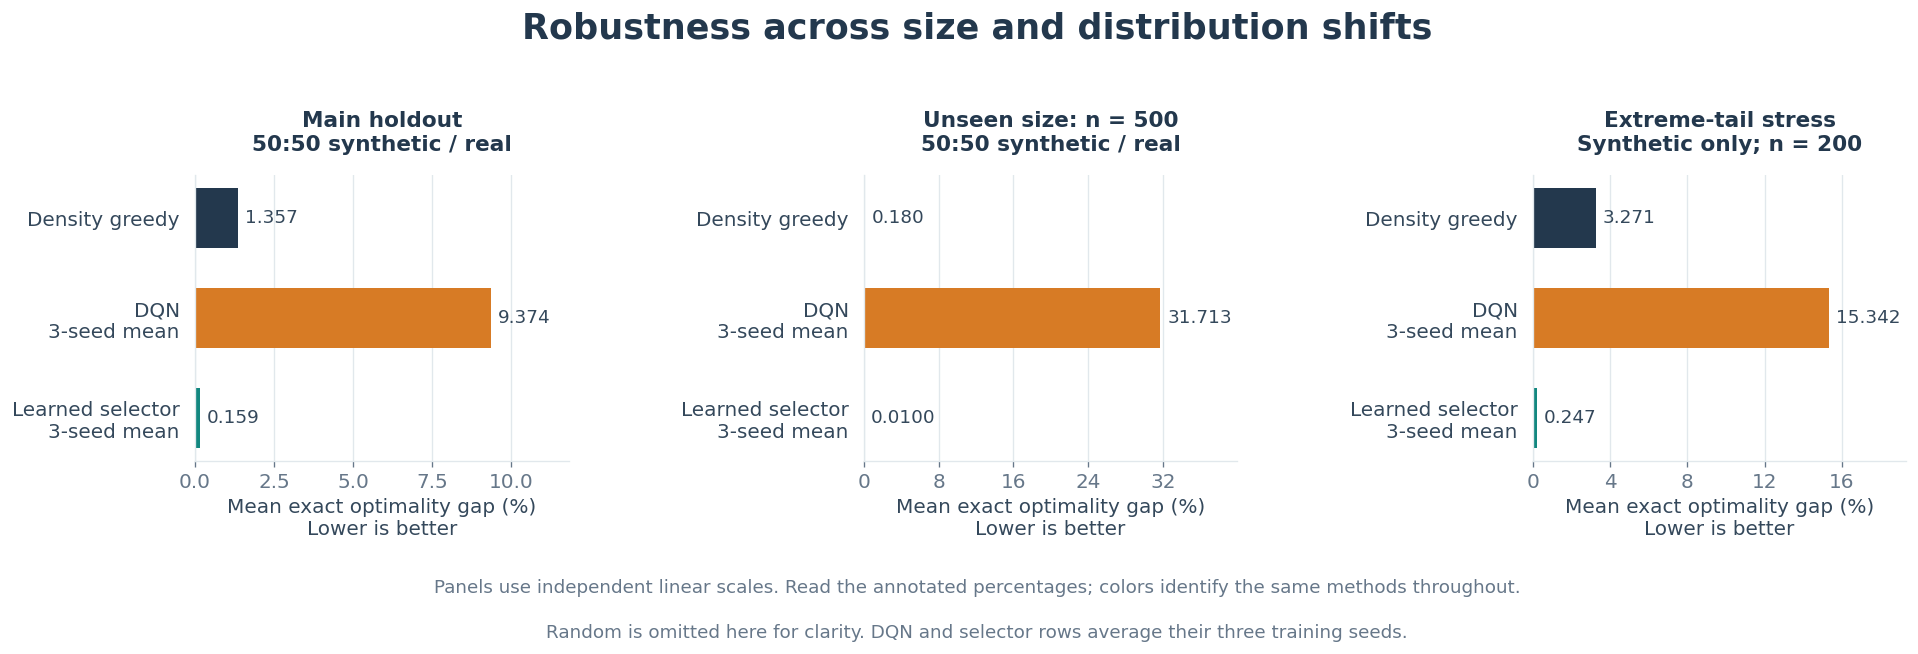

In [22]:
overall = summary.query("group == 'overall'")
stress_table = overall[overall.method.isin(primary_methods)].pivot(
    index='method', columns='split', values='exact_gap_pct_mean')
display(stress_table.loc[primary_methods, ['main', 'e3_size', 'e4_tail']])
from analysis.notebook_visuals import stress_results_figure
stress_results_figure(summary)
plt.show()

The selector's gap is **0.00998% at n=500**, compared with **31.713% for the old DQN** and
**0.17956% for greedy**. Much of this robustness comes from candidate algorithms that
naturally operate on arbitrary-length item lists. n=200 and n=500 share the selector's
final size bin; this does not demonstrate a learned neural scale-invariant representation.

Under extreme skew, the selector mean is **0.24672%**, versus **3.27087% for greedy** and
**15.34249% for DQN**. Seed variation matters: selector E4 gaps are approximately 0.079%,
0.044% and 0.617%. The third policy generalizes less well to this distribution shift.

The next breakdowns use the new main-test instances only. Source/family labels are used
for reporting, not as policy inputs. Results are descriptive; we did not tune the model
after examining a favorable subgroup.

In [23]:
group_methods = ['greedy_density', 'dqn_mean', 'selector_mean']
for dimension in ['source', 'n', 'alpha', 'family']:
    group = summary[(summary.split == 'main') & (summary.group == dimension)
                    & summary.method.isin(group_methods)]
    display(Markdown(f'**Main-test breakdown: {dimension}**'))
    display(group.pivot(index='group_value', columns='method', values='exact_gap_pct_mean')
                 .reindex(columns=group_methods))

**Main-test breakdown: source**

method,greedy_density,dqn_mean,selector_mean
group_value,,,
real,1.4225,8.7084,0.1502
synthetic,1.2908,10.0400,0.1678


**Main-test breakdown: n**

method,greedy_density,dqn_mean,selector_mean
group_value,,,
100,0.5979,8.2732,0.0658
20,3.0302,11.5655,0.3786
200,0.4658,8.0728,0.0302
50,1.3326,9.5853,0.1615


**Main-test breakdown: alpha**

method,greedy_density,dqn_mean,selector_mean
group_value,,,
0.25,1.2331,11.9773,0.2137
0.5,0.9836,8.4483,0.1634
0.75,1.8532,7.6970,0.0999


**Main-test breakdown: family**

method,greedy_density,dqn_mean,selector_mean
group_value,,,
correlated,0.4847,9.3283,0.1723
normal,0.6434,8.7828,0.2089
skewed,3.7534,14.3402,0.1578
uniform,0.2818,7.7089,0.1323


### 12.1 Which actions does the learner actually choose?

A high-level policy is easier to interpret when we can inspect its action frequencies.
In the main test, exchange repair is chosen in **95.375%, 93.958% and 89.875%** of instances
by seeds 0, 1 and 2. The remaining decisions are mainly seeded greedy, with some
value/sqrt(weight) and ordinary greedy choices. No final main-test choice uses the DQN
or 1/e action.

This shows that the learner distinguishes useful and unhelpful candidates on the present
distribution. It also shows that the current benchmark is dominated by one strong action:
the selector is not switching evenly among eight equally valuable strategies.

chosen_arm,density_sqrt,greedy_density,seeded_greedy8,swap_repair8
method,,,,
selector_seed0,1.0417,0.0000,3.5833,95.3750
selector_seed1,1.0417,0.0000,5.0000,93.9583
selector_seed2,0.0417,1.4167,8.6667,89.8750


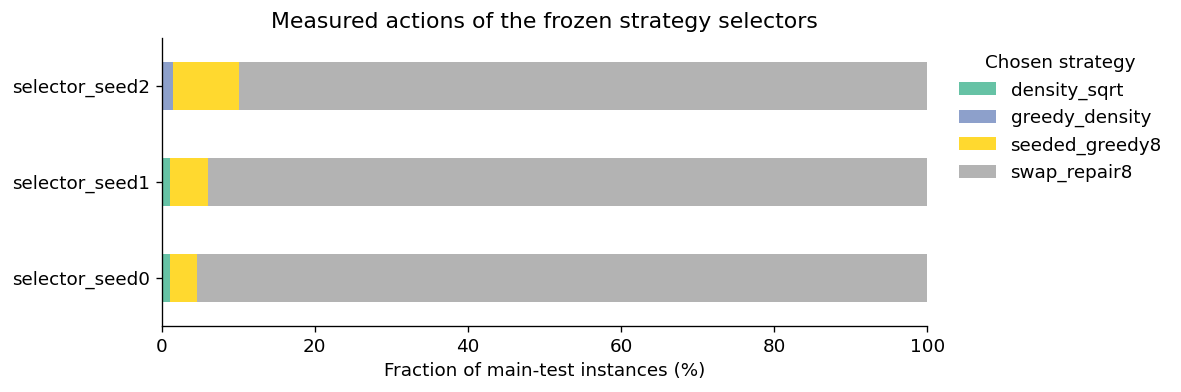

In [24]:
choices = pd.read_csv(ROOT / 'portfolio_report_tables/chosen_arms.csv')
selected = choices[(choices.split == 'main') & choices.method.str.startswith('selector_seed')]
shares = selected.pivot(index='method', columns='chosen_arm', values='share').fillna(0) * 100
display(shares)
ax = shares.plot.barh(stacked=True, figsize=(10, 3.4), colormap='Set2')
ax.set(xlabel='Fraction of main-test instances (%)', ylabel='', xlim=(0, 100),
       title='Measured actions of the frozen strategy selectors')
ax.legend(title='Chosen strategy', bbox_to_anchor=(1.02, 1), loc='upper left', frameon=False)
plt.tight_layout(); plt.show()

## 13. Supplementary comparisons: understanding where the gains come from

The project objective is to improve the original baselines through RL strategy selection.
The following methods serve as **supplementary comparisons**, not requirements that the
learned policy must defeat every available optimization procedure.

| Control | Selection rule | What it tells us |
|:--|:--|:--|
| Best fixed strategy | Select one action once on validation | How much quality is available without contextual learning? |
| Greedy-guarded selector | Run the selected action and greedy; retain higher value | Can an explicit fallback prevent losses to the original greedy baseline? |
| Full portfolio | Run all eight candidates and retain the best feasible value | What can these candidates achieve if their total cost is paid? |

The best fixed action is exchange repair. Its **0.142%** main gap is slightly lower than
the selector's **0.159%**. The paired selector-minus-fixed difference is **+0.01654 percentage
points**, with 95% interval **[+0.01264,+0.02111]**. The extra quality benefit of contextual
choice over that strong fixed method has therefore **not** been demonstrated here.

The full portfolio reaches **0.07866%**. That is a search/combination result, **not the RL
selector's score**. It guarantees the highest value among these eight candidates, not
the globally optimal integer solution. Exact DP remains the global reference.

The guarded selector achieves **0.15725%** and corrects five lower-value decisions across
all suites and seeds. Its no-loss-to-greedy guarantee comes from running greedy as a fallback,
not from a learning theorem. A greedy guard cannot fix every suboptimal strategy choice.

In [25]:
control_methods = ['selector_mean', 'fixed_best', 'guarded_mean', 'portfolio_best']
display(primary.loc[control_methods, ['exact_gap_pct_mean', 'regret_pp_to_portfolio_mean',
                                     'latency_median_s', 'loss_rate']])
display(intervals.query("split == 'main' and reference_method == 'fixed_best'")
                 [['candidate_method', 'estimate', 'ci_low', 'ci_high']])

,exact_gap_pct_mean,regret_pp_to_portfolio_mean,latency_median_s,loss_rate
method,,,,
selector_mean,0.1590,0.0803,0.0002,0.0007
fixed_best,0.1425,0.0638,0.0002,0.0000
guarded_mean,0.1573,0.0786,0.0003,0.0000
portfolio_best,0.0787,0.0000,0.0064,0.0000


,candidate_method,estimate,ci_low,ci_high
7,selector_mean,0.0165,0.0126,0.0211


### 13.1 Runtime and learning cost

Main-test median construction time is about **0.217 ms for the selector**, **0.052 ms for
greedy**, **5.896 ms for DQN**, and **6.443 ms for the full portfolio**. The selector avoids
paying for all candidates and is roughly 30 times faster than the full portfolio by this
median comparison. But the best fixed control is slightly faster still, at **0.200 ms**.

Timed evaluation includes context calculation and solver construction, including each
solver's internal capacity handling. It excludes checkpoint loading, disk I/O, reference
DP and the later independent solution audit. Calls are warmed and use one PyTorch CPU thread.
These are local single-pass measurements, not isolated cross-hardware benchmark guarantees.
Random's median is per trial; its quality averages ten trials. Three-seed timing means pool
the actual single-policy observations and are not ensemble running times.

Training the selector took 15.54 seconds including its 13.82-second simulator cache. This
excludes the historical cost of training the DQN candidate. At these small project sizes,
exact DP is also practical; a deployment requiring guaranteed optimality can use it.

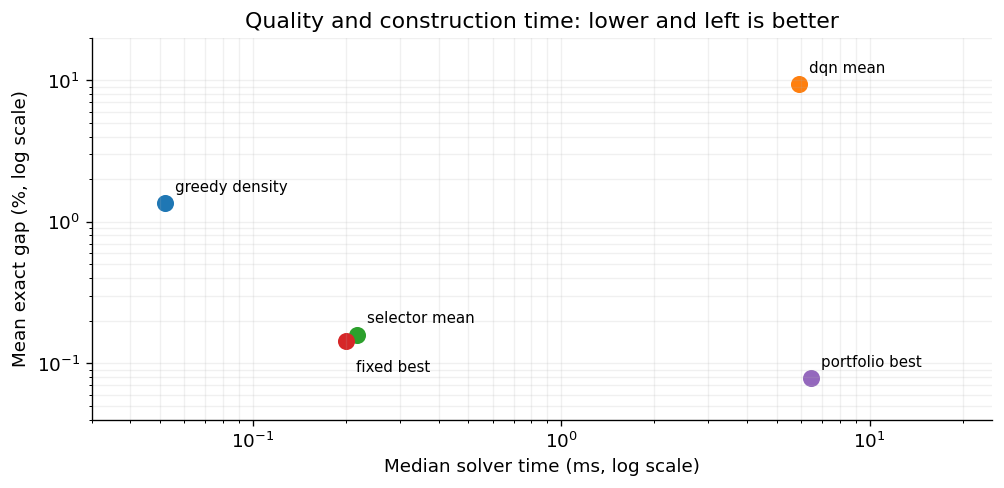

In [26]:
timed = ['greedy_density', 'dqn_mean', 'selector_mean', 'fixed_best', 'portfolio_best']
fig, ax = plt.subplots(figsize=(8.5, 4.2))
for method in timed:
    row = primary.loc[method]
    ax.scatter(row.latency_median_s * 1000, row.exact_gap_pct_mean, s=85)
    ax.annotate(method.replace('_', ' '),
                (row.latency_median_s * 1000, row.exact_gap_pct_mean),
                xytext=(6, 7 if method != 'fixed_best' else -18), textcoords='offset points', fontsize=9)
ax.set(xscale='log', yscale='log', xlabel='Median solver time (ms, log scale)',
       ylabel='Mean exact gap (%, log scale)', title='Quality and construction time: lower and left is better',
       xlim=(.03, 25), ylim=(.04, 20))
ax.grid(alpha=.18, which='both'); fig.tight_layout(); plt.show()

<a id="live"></a>
## 14. Inspect a trained decision: a runnable end-to-end demonstration

The saved selector below is **seed 1, selected on validation**. The eight examples were chosen
by stored order from training: the first n=20, alpha=0.5 example of each synthetic family and
the first four real examples meeting those settings. Selection did not inspect solver outcomes.
They demonstrate the data path and policy mechanism; they are not test evidence.

We load the small copied artifacts with checked hashes, calculate a context, inspect all
estimated action rewards, execute the selected strategy and verify capacity. The model is
frozen: no update is performed on these demonstration outcomes.

In [27]:
import torch
from experiment.rl.model import QNetwork, solve_instances
torch.set_num_threads(1)
saved_selector = load_json(BUNDLE / 'selector_seed1.json')
selector = Bandit.from_dict(saved_selector['model'])
checkpoint = torch.load(BUNDLE / 'dqn_seed0.pt', map_location='cpu', weights_only=True)
dqn = QNetwork()
dqn.load_state_dict(checkpoint['model']); dqn.eval()

def run_candidate(name, instance):
    return (solve_instances(dqn, [instance])[0] if name == 'dqn_seed0'
            else solve_strategy(name, instance))

DEMO_INDEX = 0  # Change to 0..7 and rerun this cell plus the next two cells.
instance = demo_inputs[DEMO_INDEX]
key = context_key(instance, config['context_bins'])
chosen_name = selector.arms[selector.predict(key)]
solution = run_candidate(chosen_name, instance)
display(pd.DataFrame({'Strategy': selector.arms,
                      'Estimated normalized reward': selector.estimates(key)})
            .sort_values('Estimated normalized reward', ascending=False))
print('Context:', key, '| chosen strategy:', chosen_name)
print('Value:', solution.value, '| capacity used:', solution.weight_used, '/', instance['capacity'])
assert solution.weight_used <= instance['capacity']

,Strategy,Estimated normalized reward
6,swap_repair8,0.9865
5,seeded_greedy8,0.9820
3,density_sqrt,0.9756
0,greedy_density,0.9742
1,value_first,0.9191
7,dqn_seed0,0.9159
2,light_first,0.8214
4,one_e_threshold,0.1392


Context: (0, 1, 1, 1) | chosen strategy: swap_repair8
Value: 789 | capacity used: 532 / 536


In [28]:
reference = exact_solve(instance)  # Evaluation only; never passed to selector.predict.
candidates = [(name, run_candidate(name, instance)) for name in selector.arms]
demo_table = pd.DataFrame([
    {'Strategy': name, 'Value': s.value, 'Weight used': s.weight_used,
     'Exact gap (%)': 100 * (reference.value - s.value) / reference.value,
     'Chosen by RL': name == chosen_name}
    for name, s in candidates])
assert all(s.weight_used <= instance['capacity'] and s.value <= reference.value for _, s in candidates)
display(demo_table.sort_values('Value', ascending=False))
print('Exact optimum:', reference.value, '| learned-selector value:', solution.value)
print('All-candidate comparison in this cell is an explanation, not extra policy information.')

,Strategy,Value,Weight used,Exact gap (%),Chosen by RL
0,greedy_density,789,532,0.0000,False
3,density_sqrt,789,532,0.0000,False
6,swap_repair8,789,532,0.0000,True
5,seeded_greedy8,789,532,0.0000,False
1,value_first,730,533,7.4778,False
7,dqn_seed0,723,525,8.3650,False
2,light_first,637,470,19.2649,False
4,one_e_threshold,230,60,70.8492,False


Exact optimum: 789 | learned-selector value: 789
All-candidate comparison in this cell is an explanation, not extra policy information.


### 14.1 Why “expected best” is not “best on every instance”

Another compact example has weights `[10,20,30]`, values `[60,100,120]` and capacity 50.
Greedy takes items 0 and 1 for 160. Value-first can take items 1 and 2 for 220, which is optimal.
The full portfolio can compare these outcomes and return 220. The saved learned selector
actually chooses greedy and returns 160 on this n=3 input, outside the training sizes.

We show this failure as well as successful comparisons. It prevents a misleading presentation
in which a hand-chosen good algorithm is described as the learned agent's decision. You can
change the values/capacity below to explore how candidate preferences differ.

In [29]:
custom = {'weights': [10, 20, 30], 'values': [60, 100, 120],
          'capacity': 50, 'n': 3, 'item_order': [0, 1, 2]}
custom_arm = selector.arms[selector.predict(context_key(custom, config['context_bins']))]
custom_results = {name: run_candidate(name, custom).value for name in selector.arms}
display(pd.Series(custom_results, name='Value').to_frame())
print('Learned choice:', custom_arm, '->', custom_results[custom_arm])
print('Best of all candidates:', max(custom_results.values()))
print('Certified optimum:', exact_solve(custom).value)
assert max(custom_results.values()) == 220

,Value
greedy_density,160
value_first,220
light_first,160
density_sqrt,220
one_e_threshold,0
seeded_greedy8,180
swap_repair8,180
dqn_seed0,160


Learned choice: greedy_density -> 160
Best of all candidates: 220
Certified optimum: 220


## 15. When is this approach useful, and what remains uncertain?

### Suitable use cases

A learned selector is most attractive when an organization solves **many related instances**,
observes the outcomes of its chosen strategies, and has several algorithms with different
strengths. Instance statistics can help choose among them. If running every algorithm is
expensive, selecting one promising method can reduce computation substantially.

Examples include repeated warehouse allocation, workload allocation and recurring scheduling
tasks with heterogeneous sizes or resource pressure. These are motivations for algorithm
selection; the experiment directly validates only the stated knapsack benchmark.

| Situation | Reasoned implication |
|:--|:--|
| Repeated instances with useful context and complementary solvers | Learning selection is a plausible way to reuse experience |
| One solver dominates almost all instances | A fixed strategy may be simpler and better; our repair control illustrates this |
| All candidates are cheap and final value is the only priority | Running the full portfolio may be preferable |
| Guaranteed global optimum is needed at tractable sizes | Use the exact solver |
| Future arrivals are unknown and capacity must be reserved | A sequential RL formulation may be more appropriate |

A dynamic freight-booking experiment would introduce genuinely unknown future requests,
remaining time, acceptance decisions and opportunity cost. [Dumouchelle, Frejinger and Lodi](https://arxiv.org/abs/2102.00092)
study RL in freight booking control. Such an extension would need a new arrival model and
fair information access for every policy. It is **future work**, not a completed feature here.

### Limits of the current evidence

1. **Candidate quality matters.** Most measured gains are available from strong repair/search
   candidates; contextual selection has not exceeded the best fixed candidate.
2. **Representation is coarse.** Four binned statistics cannot describe every combinatorial
   interaction. A context can contain instances with different best actions.
3. **The real data are a proxy.** Sales and quantities are transformed into an imposed allocation
   model. Neither realized profit nor physical freight mass is validated.
4. **The business cohort is reused.** Fresh combinations do not create an independent time period.
   Chronological splits also do not imply unseen products or customers.
5. **The policy is fixed at test time.** It does not automatically adapt online to a new regime.
6. **The comparison is not an equal-budget ablation.** DQN and strategy selection differ in
   training coverage, actions and algorithmic prior knowledge.
7. **Timing is local.** Training cost and hardware matter; medians alone do not establish
   production throughput or end-to-end startup latency.

These limits define the scope of the contribution rather than invalidating the measured
improvement over the original baselines.

<a id="conclusion"></a>
## 16. Conclusions

**The main lesson is that RL can learn how to use optimization algorithms.** Its actions
need not be low-level item choices. In this project, moving from sequential DQN construction
to contextual strategy selection yields much better feasible solutions than the original
random, greedy and DQN baselines on a balanced mixed-source benchmark.

The project demonstrates a complete research workflow:

- Translate a resource-allocation question into an explicit optimization model.
- Prepare audited synthetic and public-data-derived instances with leakage-aware splits.
- Establish exact references and simple baselines before interpreting learned behavior.
- Retain an unsuccessful DQN comparison and use it to motivate a revised learning problem.
- Train a reward-based strategy selector and evaluate it on a frozen follow-up instance set.
- Report accuracy, feasibility, timing, robustness, uncertainty and meaningful controls.

**Seminar takeaway:** the learned selector's **0.159%** main exact gap improves on greedy's
**1.357%** and the frozen DQN's **9.374%**. The **0.142% fixed-strategy** and **0.079% full-portfolio**
results are supplementary comparisons. They explain the role of the candidate library;
the 0.079% result must never be presented as the RL score.

A defensible project claim is: **“Reinforcement learning can effectively select optimization
strategies from historical rewards and improve the original baselines on this benchmark.”**
A stronger claim that RL is always necessary, always optimal, or better than every heuristic
is not supported and is not required for this course project.

## 17. Reproducibility, verification and project map

The original and follow-up experiments are bound to configuration, data, code and checkpoint
hashes. The completed code suite recorded **559 passing tests**. An independent follow-up
audit checked all **92,400 recorded method outcomes**, **9,900 learned decisions**, guarded
solutions, portfolio maxima, validation choices, **704 summary rows** and **24 paired intervals**.
Its numerical results agreed within 2.84e-14. Those counts describe the saved experiment audit;
this notebook verifies its own inputs and demonstrations rather than pretending to rerun that
entire audit in a classroom.

| Location | Role |
|:--|:--|
| `experiment/data/` | Downloading, cleaning, generation and assembly |
| `experiment/eval/` | Exact reference solver and metrics |
| `experiment/baselines/` | Random and greedy |
| `experiment/rl/` | Original DQN environment, model and training |
| `portfolio/` | Candidate strategies, contextual learner, holdout and evaluation |
| `portfolio_config.json` | Frozen follow-up settings |
| `report_tables/` | Original published experiment tables |
| `portfolio_report_tables/` | Follow-up tables, uncertainty and audit |
| `assets/notebook/` | Small copied/sampled artifacts with provenance for live demonstrations |
| `analysis/notebook_visuals.py` | Readable figure helpers used by this notebook |
| `report.ipynb` / `report.html` | Executable report / static presentation companion |

Large datasets and run directories are Git-ignored. Keep them when reproducing full experiments.
The delivered notebook's default cells use only the code, published tables and compact bundle,
so they do not depend on those large directories being present.

In [30]:
independent = load_json(ROOT / 'portfolio_report_tables/independent-audit.json')
print('Saved independent audit status:', independent['status'])
print('Maximum numerical discrepancy:', independent['max_absolute_numeric_discrepancy'])
print('Audit counts:')
display(pd.json_normalize(independent['counts']).T.rename(columns={0: 'Count'}))
import importlib.metadata as metadata
display(pd.DataFrame({'Package': ['numpy', 'pandas', 'torch', 'matplotlib', 'nbformat', 'ipykernel'],
                      'Current notebook environment': [metadata.version(p) for p in
                      ['numpy', 'pandas', 'torch', 'matplotlib', 'nbformat', 'ipykernel']]}))

Saved independent audit status: passed
Maximum numerical discrepancy: 2.842170943040401e-14
Audit counts:


,Count
feasibility_violations,0
guarded_decisions_verified,9900
independent_fractional_bounds,3300
instances,3300
methods,28
numeric_checks,7592
paired_intervals,24
portfolio_maxima_verified,3300
reference_selected_sets_verified,3300
selector_predictions_verified,9900


,Package,Current notebook environment
0,numpy,2.5.3
1,pandas,3.0.6
2,torch,2.8.0+cpu
3,matplotlib,3.10.7
4,nbformat,5.11.1
5,ipykernel,7.4.0


### 17.1 Running the notebook

Use the existing project environment. Notebook dependencies are recorded separately so the
frozen experiment configuration remains unchanged.

```powershell
.\venv\Scripts\python.exe -m pip install -r requirements-notebook.txt
```

Open `report.ipynb` in a notebook-capable editor and select `venv/Scripts/python.exe`.
The installed kernel tools support this selection; a separate JupyterLab installation is
optional. In a browser, open `report.html` to read saved text, tables and figures.
HTML equation typesetting may use a MathJax CDN; formulas remain readable as text if offline.

The authoring utilities below regenerate the report from its source. They are not required
during the presentation. Rebuilding resets the notebook before execution, so preserve manual
notebook edits separately if you choose to use the builder later.

```powershell
.\venv\Scripts\python.exe -m analysis.build_report_notebook
.\venv\Scripts\python.exe -m analysis.execute_report_notebook
```

### 17.2 Optional full experiment reproduction — do not run during a short presentation

These commands require the original prepared corpus and completed original DQN checkpoints.
The original data pipeline is documented in `EXPERIMENT_PLAN.md`; the original DQN training
protocol is documented in `RL_IMPLEMENTATION.md` and `EXPERIMENT_REPORT.md`. The commands below
reproduce the follow-up without overwriting the saved experiment. Each output path must be new.

```powershell
.\venv\Scripts\python.exe -m portfolio.run freeze --out results/class-demo-freeze.json
.\venv\Scripts\python.exe -m portfolio.run train --freeze results/class-demo-freeze.json --out results/class-demo-training
.\venv\Scripts\python.exe -m portfolio.holdout --out results/class-demo-holdout
.\venv\Scripts\python.exe -m portfolio.run evaluate --freeze results/class-demo-freeze.json --training results/class-demo-training --holdout results/class-demo-holdout --out results/class-demo-evaluation
.\venv\Scripts\python.exe -m portfolio.report --evaluation results/class-demo-evaluation --out results/class-demo-comparison
```

For a single input, the existing CLI also supports `--mode learned`, `--mode guarded`, and
`--mode best`. The last mode runs all candidates; it is not the learned-selector experiment.

```powershell
.\venv\Scripts\python.exe -m portfolio.solve --instance portfolio/example.json --mode learned
```

## 18. Presentation Q&A

**Q: Are all eight candidate strategies RL?**  
No. Seven are hand-designed heuristics and one is the original DQN. The upper-level selector
learns which action to take from context and rewards; that selection mechanism is the main
contextual-bandit method.

**Q: Why call this reinforcement learning if there is only one decision per instance?**  
A contextual bandit is a one-step reward-learning formulation. The agent chooses an action
and updates from its observed reward. It has no multi-step return or next-state bootstrap.
This distinction is stated explicitly so it is not confused with the sequential DQN.

**Q: Does the model receive the correct strategy as a supervised label?**  
No. The simulator cache stores outcomes for efficiency, but each update exposes only the
selected action's reward. No best-action label or exact-DP solution is passed to the learner.

**Q: Why not always use greedy?**  
Ordinary density greedy is fast but can make poor indivisible combinations. Its main gap
of 1.357% is materially higher than the selector's 0.159%. A stronger fixed repair heuristic
is a different baseline; it is retained as a useful supplementary comparison.

**Q: Why not always use the strongest fixed strategy?**  
On this corpus that is a reasonable practical choice. The selector does not beat it. The
course project demonstrates the learning mechanism and improvement over the original
baselines; heterogeneous tasks with stronger solver complementarity are a natural next study.

**Q: Is 0.079% the RL result?**  
No. It is the result of running all eight candidates. The main RL selector result is 0.159%.

**Q: Did RL learn to anticipate unknown future cargo?**  
No. The current instance is fully known. Dynamic booking under uncertain future arrivals
is a possible future project, not an interpretation of these experiments.

**Q: Are the real datasets actually warehouse and airline loading records?**  
No. We use public retail transactions transformed into handling-budget allocation instances.
The transformation, units and limitations are explicit.

**Q: Why are the old and new DQN averages different?**  
The policy is frozen but evaluated on different instance sets. The old 9.521% and follow-up
9.374% results must not be mixed within a same-instance comparison.

**Q: Why not solve everything exactly?**  
At these sizes we can, and we do for evaluation. Exact references make the learning experiment
measurable. The project studies learned strategy selection rather than claiming a computational
necessity for RL on these small knapsacks.

**Q: What would a stronger next experiment test?**  
Predefine a new independent business period or application, a richer but non-leaking context,
complementary solvers, and a fixed training budget. Preserve the current baselines and use
validation-only selection before opening the new test results.

## 19. References and supporting artifacts

1. **Chen, D. (2015). Online Retail.** UCI Machine Learning Repository.
   [Dataset and license](https://archive.ics.uci.edu/dataset/352/online+retail),
   [DOI: 10.24432/C5BW33](https://doi.org/10.24432/C5BW33).
   Source of public transaction data; the project creates a derived optimization representation.
2. **Mnih et al. (2015). Human-level control through deep reinforcement learning.** Nature.
   [DOI: 10.1038/nature14236](https://www.nature.com/articles/nature14236).
   Background on neural action-value learning, replay and target networks; not evidence of
   performance on this project's knapsack instances.
3. **Li, Chu, Langford and Schapire (2010). A Contextual-Bandit Approach to Personalized
   News Article Recommendation.** [Paper](https://arxiv.org/abs/1003.0146).
   Background on context-dependent reward feedback; this project does not implement LinUCB.
4. **Babaioff, Immorlica, Kempe and Kleinberg (2007). A Knapsack Secretary Problem with
   Applications.** [Publication](https://www.microsoft.com/en-us/research/publication/a-knapsack-secretary-problem-with-applications/).
   Explains why weighted online selection requires its own assumptions and algorithms.
5. **Dumouchelle, Frejinger and Lodi. Reinforcement Learning for Freight Booking Control
   Problems.** [Paper, revised 2023](https://arxiv.org/abs/2102.00092).
   Motivation for a future genuinely sequential booking-control setting.

**Project evidence:** [Original experiment](EXPERIMENT_REPORT.md),
[portfolio follow-up](PORTFOLIO_REPORT.md), [data/experiment plan](EXPERIMENT_PLAN.md),
[frozen portfolio configuration](portfolio_config.json),
[all follow-up tables](portfolio_report_tables/tables.md),
[group metrics](portfolio_report_tables/summary.csv),
[paired intervals](portfolio_report_tables/paired_bootstrap.csv),
[independent audit](portfolio_report_tables/independent-audit.json),
[demo-bundle provenance](assets/notebook/manifest.json).

**One-sentence closing statement:** this project shows how a reward-trained agent can
improve constrained-allocation decisions by learning which optimization strategy to use,
while retaining the baselines and controls needed to explain that improvement.